# WikiPulse — Network analysis

**Research question 1:** which collection method — **Selenium** (headless Chrome), **requests + BeautifulSoup**, or the
**MediaWiki Action API** — is the most efficient, reliable and timely way to collect English Wikipedia's Recent Changes?

**Setup.** Windows 11 + WSL2 Ubuntu 24.04 (Python 3.12, Chrome 157); all runs from the same machine and network.
**Workload:** the newest 500 main-namespace edits (bots included, log entries excluded) — the same records for every method.
**Two measurement layers:**
1. *Application level* — our own instrumentation (requests timers/byte counters; Chrome DevTools network log).
2. *Packet level* — `tcpdump -i any port 80 or 443` → pcap parsed with scapy and checked in Wireshark.
HTTPS hides payloads, so request counts/latencies come from layer 1; bytes, packets, connections, TLS handshakes and
retransmissions come from layer 2.

Every number below is read from files written by real runs (`experiments/metrics/`); nothing is typed in by hand.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display, Markdown
M, FIG, SHOT = ROOT / "experiments" / "metrics", ROOT / "reports" / "figures", ROOT / "experiments" / "screenshots"
pd.set_option("display.max_columns", 40, "display.width", 180)
def show(path, width=900):
    """Display a figure or screenshot from the repo (all files were produced by real runs)."""
    p = Path(path)
    if p.exists():
        display(Image(filename=str(p), width=width))
    else:
        print("missing:", p)

## 1. What each method can see (Phase 0 probes + Phase 2 cross-check)

| Field | Selenium / BS4 (HTML page) | API |
|---|---|---|
| rev_id, timestamp, title, page_id, editor, byte change, flags, tags | yes | yes |
| new size (page tooltip) → old size derived | yes | yes (oldlen/newlen) |
| rc_id, user_id | no (null) | yes |
| edit summary | rendered text | raw wikitext |

In [2]:
xv = pd.read_csv(M / "cross_validation_xval1_api.csv")
xv.pivot(index="field", columns="method", values="agree_pct").rename(columns=lambda c: f"{c} vs api, % agree")

method,"bs4 vs api, % agree","selenium vs api, % agree"
field,,
byte_change,100.00,100.00
edit_summary,21.56,21.93
editor,100.00,100.00
is_anonymous,100.00,100.00
is_bot,100.00,100.00
is_minor,100.00,100.00
is_new_page,100.00,100.00
namespace,100.00,100.00
new_size,100.00,100.00


On edits seen by both methods, all structural fields agree **100 %**; only the summary differs (rendered text vs wikitext). BS4 and Selenium agree 100 % on every field (same HTML, different transport).

## 2. Benchmark — the required metrics table (5 rounds × 3 methods, rotated order, cold start each run)

In [3]:
runs = pd.read_csv(M / "bench_main.runs.csv")
runs = runs[runs.collection_status == "ok"]
def table(r):
    g = r.groupby("method")
    fmt = lambda s, nd: s.map(lambda v: f"{v:.{nd}f}")   # same rounding as the runner's console table
    f = lambda c, nd: fmt(g[c].mean(), nd) + " ± " + fmt(g[c].std(), nd)
    return pd.DataFrame({"Bandwidth (KB)": f("bandwidth_kb", 1), "Time (s)": f("time_s", 2),
                         "#Requests": f("n_requests", 1), "Avg latency (ms)": f("avg_latency_ms", 0),
                         "Main-page latency (ms)": f("main_latency_ms", 0), "runs": g.size()}).loc[["api", "bs4", "selenium"]]
table(runs)

,Bandwidth (KB),Time (s),#Requests,Avg latency (ms),Main-page latency (ms),runs
method,,,,,,
api,36.8 ± 0.5,9.42 ± 1.35,1.0 ± 0.0,9254 ± 1347,9254 ± 1347,5
bs4,123.6 ± 0.4,11.41 ± 0.31,1.0 ± 0.0,9487 ± 328,9487 ± 328,5
selenium,656.2 ± 4.3,31.15 ± 18.16,16.8 ± 0.4,1357 ± 495,10208 ± 1745,5


**Selenium's time has a large std** because run 1 included a one-off download by Selenium Manager (driver metadata, ~6 MB
from `googlechromelabs.github.io`, browser startup 30.5 s). Without that cold-start run:

In [4]:
table(runs[~((runs.method == "selenium") & (runs["round"] == 1))]).loc[["selenium"]]

,Bandwidth (KB),Time (s),#Requests,Avg latency (ms),Main-page latency (ms),runs
method,,,,,,
selenium,655.5 ± 4.5,23.19 ± 4.14,16.8 ± 0.5,1191 ± 378,9476 ± 699,4


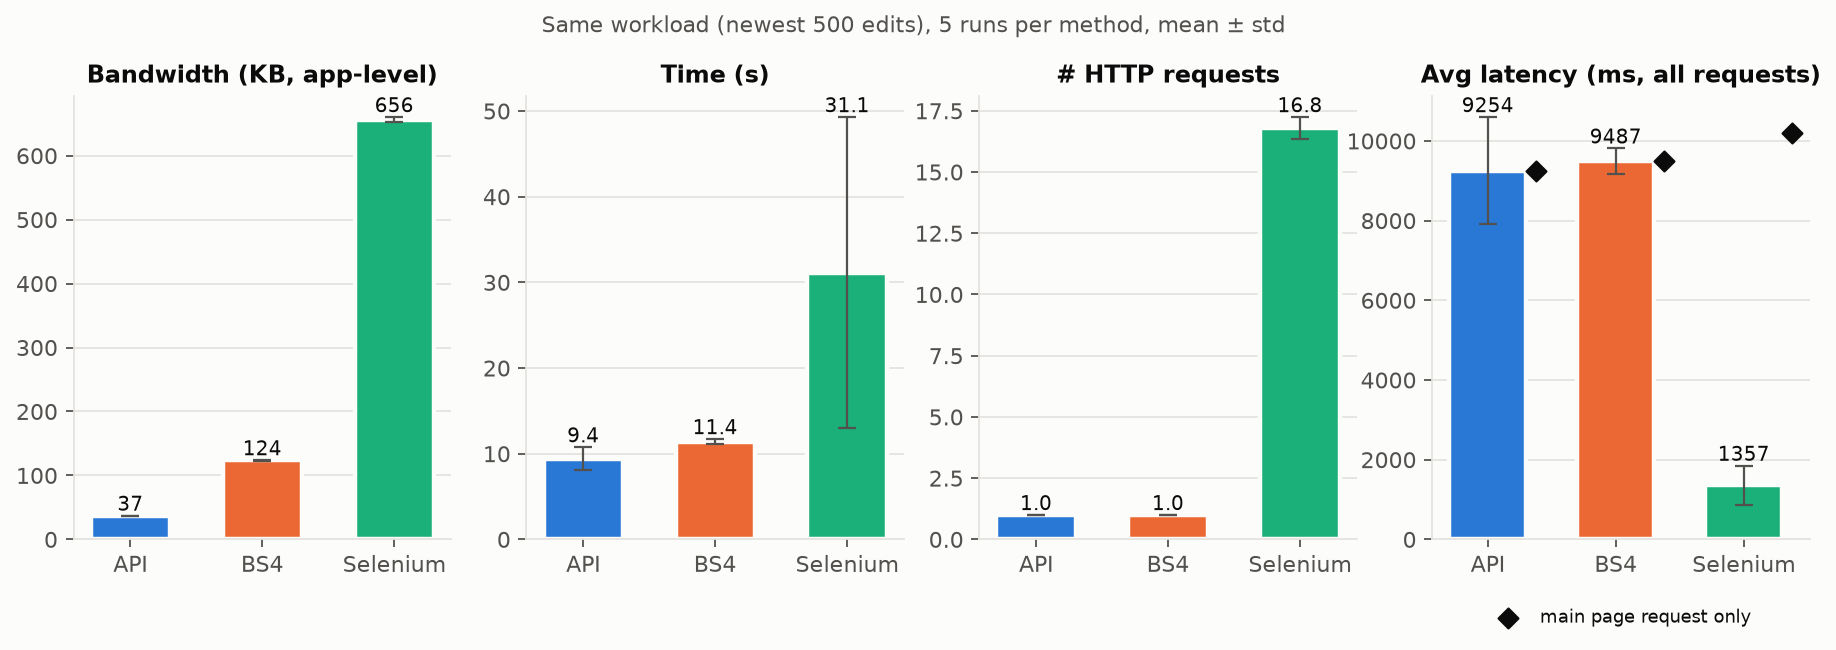

In [5]:
show(FIG / "bench_main_required_metrics.png", 1100)

**Reading the latency column.** "Avg latency over all requests" makes Selenium look fastest (≈1.4 s) only because 15 of
its ~17 requests are small static assets served quickly from Wikimedia's CDN cache. The request that carries the data
(the page itself) is as slow as for BS4 and the API (≈9–10 s): it is the **server's database query** that takes time.
A `curl -w` breakdown in Phase 1 showed DNS 0.02 s, TCP 0.07 s, TLS 0.14 s, then ~8.7 s waiting for the first byte.

In [6]:
cols = ["records", "time_s", "startup_s", "network_s", "parse_s", "python_cpu_s", "kb_per_record",
        "records_per_s", "freshness_newest_s", "n_requests_supplementary", "bandwidth_kb_supplementary"]
runs.groupby("method")[cols].mean().round(2).T

method,api,bs4,selenium
records,500.00,500.00,500.00
time_s,9.42,11.41,31.15
startup_s,0.00,0.00,6.60
network_s,9.39,10.19,18.52
parse_s,0.00,1.17,4.16
python_cpu_s,0.07,1.26,3.76
kb_per_record,0.07,0.25,1.31
records_per_s,54.02,43.84,19.22
freshness_newest_s,12.62,14.74,27.10
n_requests_supplementary,0.00,0.00,15.80


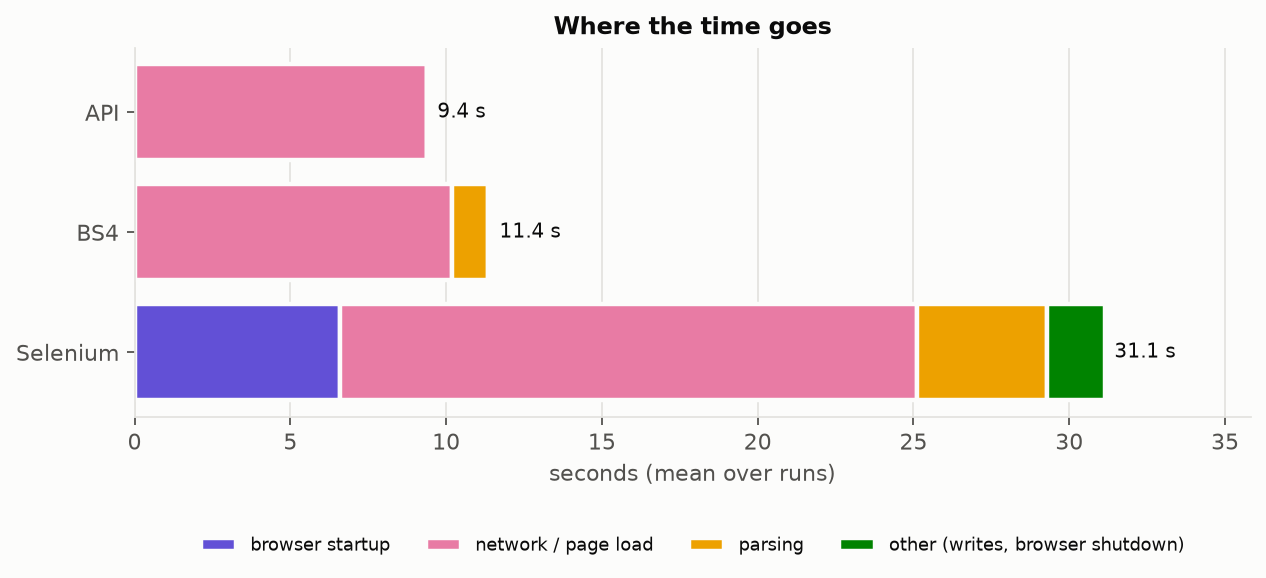

In [7]:
show(FIG / "bench_main_time_breakdown.png", 900)

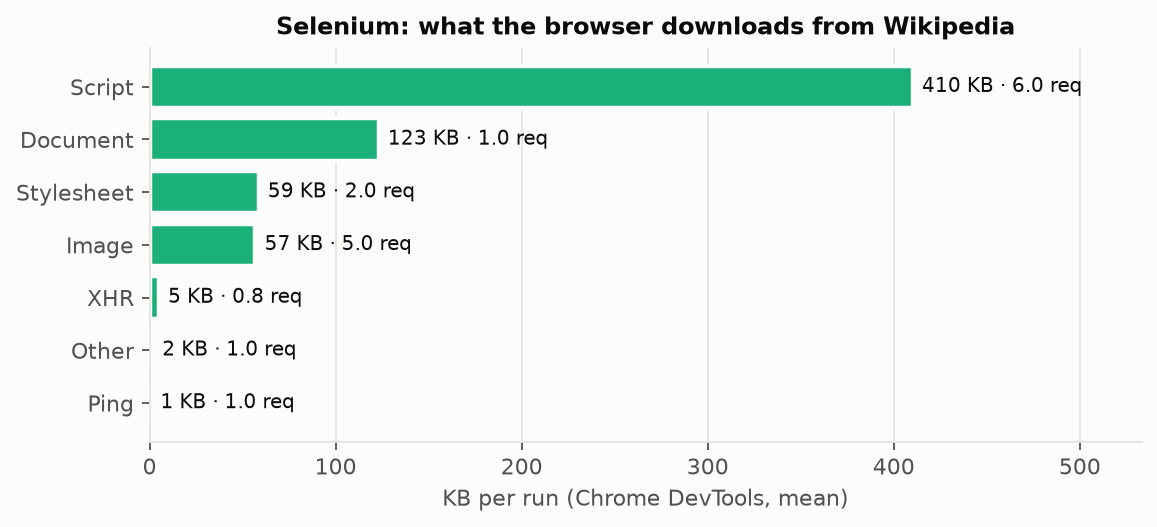

In [8]:
show(FIG / "bench_main_selenium_resources.png", 800)

- **Bandwidth per record:** API ≈ 0.07 KB, BS4 ≈ 0.25 KB, Selenium ≈ 1.3 KB (app level).
- **Freshness** (age of the newest edit at the end of a run) follows run time: the faster method sees fresher data.
- **Application overhead:** BS4 spends ~1 s parsing HTML; Selenium adds browser start-up and rendering on top of the page load.

## 3. Packet capture — what actually crossed the network

In [9]:
pm = pd.read_csv(M / "scraper_trace.per_method.csv").set_index("method")
pm[["bandwidth_kb", "pcap_kb_total", "pcap_packets", "tcp_connections", "tls_handshakes",
    "retransmissions", "out_of_order", "requests_per_connection", "pcap_overhead_pct"]]

,bandwidth_kb,pcap_kb_total,pcap_packets,tcp_connections,tls_handshakes,retransmissions,out_of_order,requests_per_connection,pcap_overhead_pct
method,,,,,,,,,
api,36.8,48.0,70.2,1.0,1.0,1.4,1.6,1.00,30.4
bs4,123.6,144.4,168.2,1.0,1.0,4.2,11.2,1.00,16.8
selenium,656.2,10127.6,10536.0,13.6,10.8,150.6,478.6,1.24,1443.4


In [10]:
sp = pd.read_csv(M / "scraper_trace.traffic_split.csv")
sp.groupby("method")[["app_kb", "target_kb", "target_packets", "target_tcp_connections", "target_retrans",
                      "target_out_of_order", "other_kb", "other_quic_kb"]].agg(["mean", "std"]).round(1)

app_kb      target_kb       target_packets        target_tcp_connections      target_retrans      target_out_of_order       other_kb         other_quic_kb        
           mean  std      mean   std           mean    std                   mean  std           mean  std                mean   std     mean     std          mean     std
method                                                                                                                                                                     
api        36.8  0.5      48.0   2.3           70.2   12.0                    1.0  0.0            1.4  1.7                 1.6   3.0      0.0     0.0           0.0     0.0
bs4       123.6  0.4     144.4   1.9          168.2   17.1                    1.0  0.0            4.2  2.3                11.2  13.9      0.0     0.0           0.0     0.0
selenium  656.2  4.3     756.1  14.1          753.4  153.7                    2.8  0.4           18.4  7.9                64.2  42.0   9371.6  4418.2        6869.4  2041.6

`target_*` = traffic to Wikimedia servers (TLS SNI `*.wikipedia.org` / `*.wikimedia.org`); `other_*` = everything else
the process tree sent. **API and BS4 send nothing else. Headless Chrome sends ~9.4 MB per run to Google services**
(component updates, optimization models, account checks), mostly over **QUIC (HTTP/3, UDP 443)** — none of it appears in
the page's DevTools log; only the packet capture reveals it.

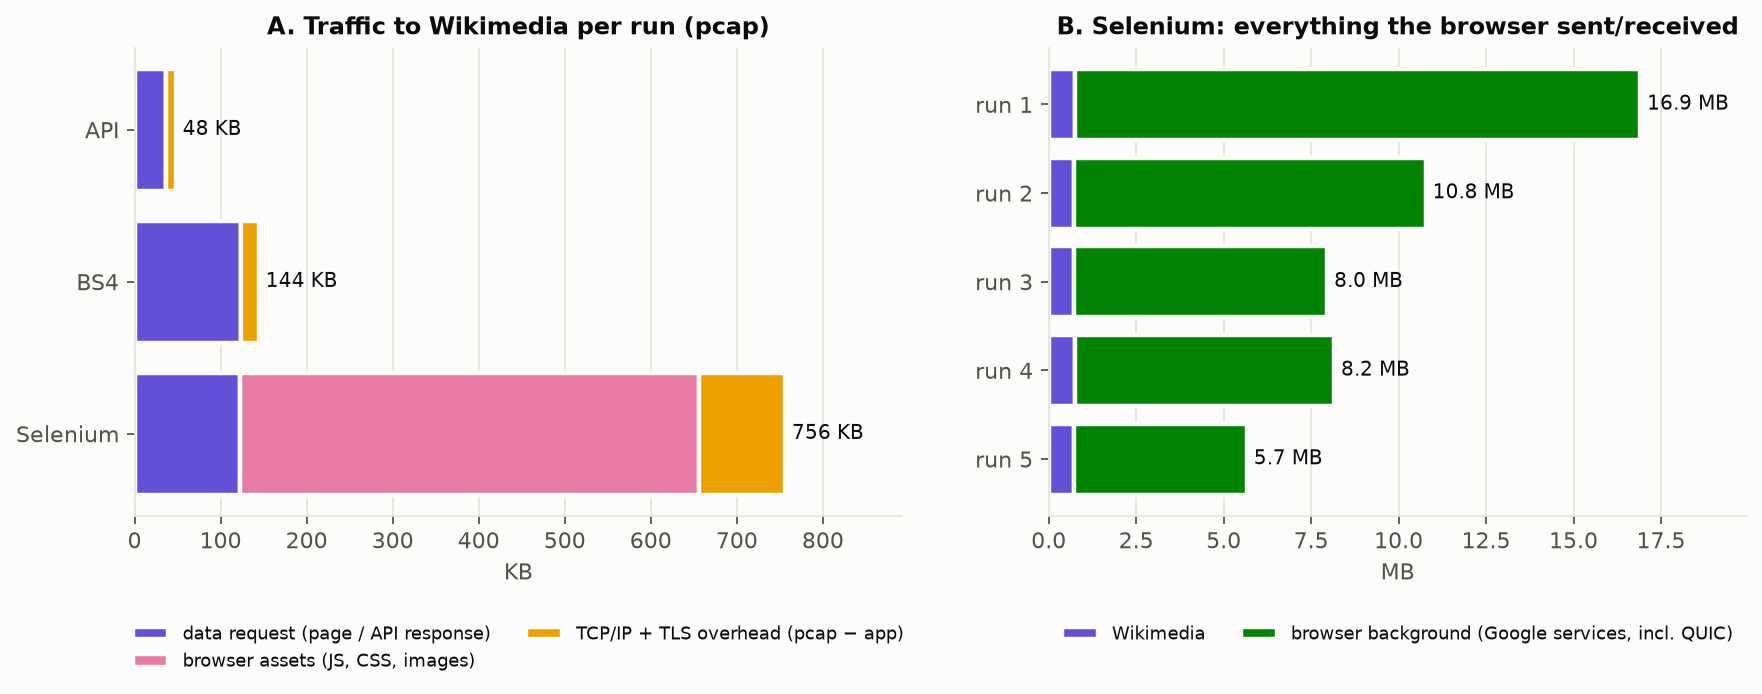

In [11]:
show(FIG / "bench_main_bandwidth_breakdown.png", 1100)

In [12]:
fl = pd.read_csv(M / "scraper_trace.flows.csv")
(fl.groupby(fl.sni.fillna("(no SNI seen)"))
   .agg(tcp_flows=("client", "size"), kb_down=("bytes_down", lambda b: round(b.sum() / 1024)),
        tls_handshakes=("tls_client_hellos", "sum"), retransmissions=("retransmissions", "sum"))
   .sort_values("kb_down", ascending=False))

,tcp_flows,kb_down,tls_handshakes,retransmissions
sni,,,,
googlechromelabs.github.io,1,5986,1,297
optimizationguide-pa.googleapis.com,15,5690,15,341
en.wikipedia.org,22,4551,22,120
(no SNI seen),14,112,0,2
update.googleapis.com,10,81,10,4
content-autofill.googleapis.com,5,40,5,8
accounts.google.com,5,37,5,5
www.google.com,5,24,5,2
plausible.io,1,9,1,2


**Cross-checks with Wireshark:** 78 TCP flows in our parser = 78 SYN packets in Wireshark (screenshot 12); 83 ClientHello
packets (TLS + QUIC) in Wireshark (screenshot 10). Retransmissions differ by tool because Wireshark also counts
"spurious" and "fast" retransmissions with timing heuristics (1,662 in screenshot 13) — most belong to the large Google /
GitHub downloads, not to Wikipedia traffic. Our parser separates real resends from out-of-order arrivals.

**Connection reuse:** API and BS4 use one TCP+TLS connection per run (one request). Chrome multiplexed all its Wikipedia
requests over HTTP/2 on 2–3 connections (DevTools showed 1 connection for 17 requests in Phase 2).

## 4. Evidence from the Linux tools (screenshots)

### tcpdump, ss

**01_tcpdump_running.png**

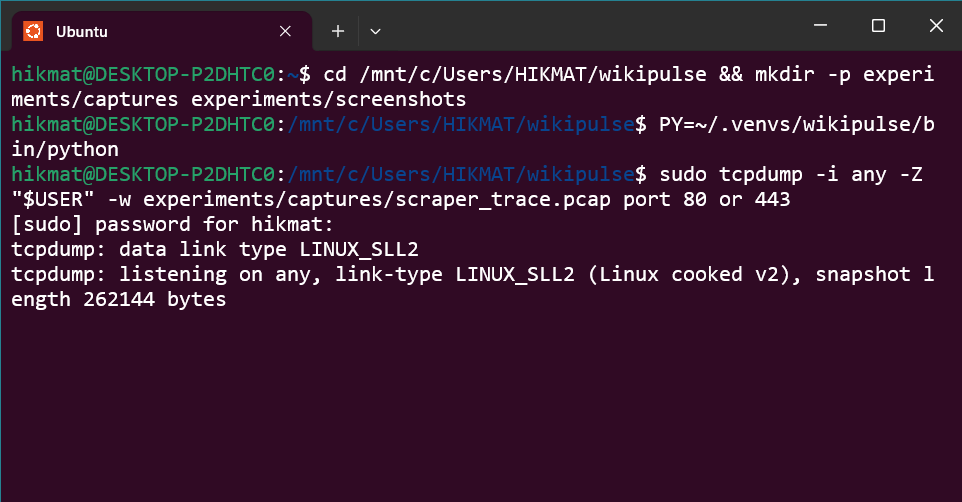

**02_ss_log.png**

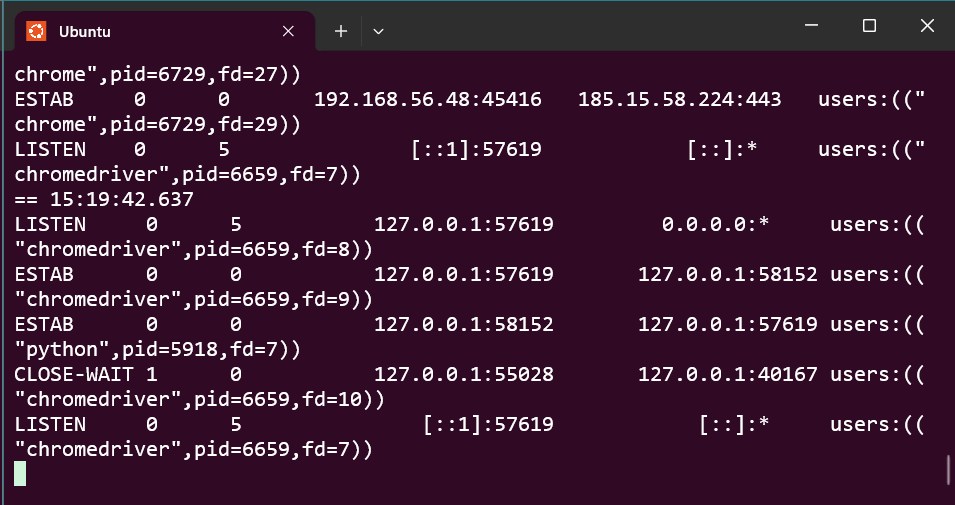

**07_ss_live_selenium.png**

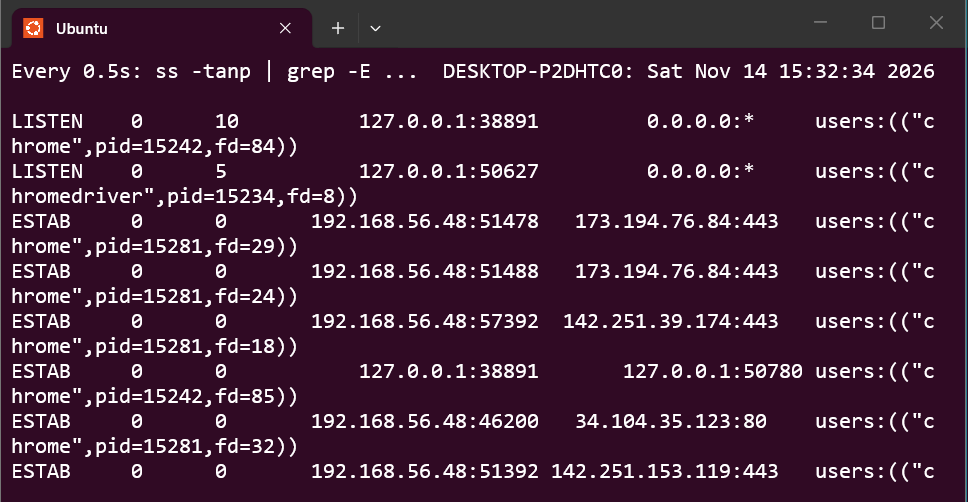

**08_ss_live_python.png**

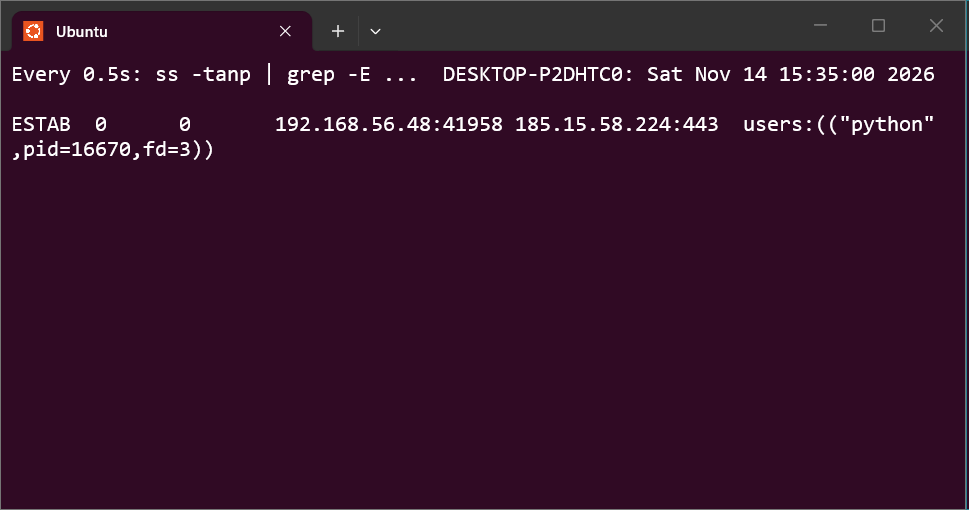

In [13]:
for f in ["01_tcpdump_running.png", "02_ss_log.png", "07_ss_live_selenium.png", "08_ss_live_python.png"]:
    display(Markdown(f"**{f}**")); show(SHOT / f, 700)

`ss -tanp` shows the owning process: one `python` connection to `185.15.58.224:443` for BS4/API, several `chrome` connections (Wikipedia **and** Google, even port 80) for Selenium; `python` ↔ `chromedriver` on localhost is the WebDriver control channel. (The PDF's `ss -t -a | grep python` prints nothing: without `-p` there is no process name.)

### iftop, nload

**04_iftop_selenium.png**

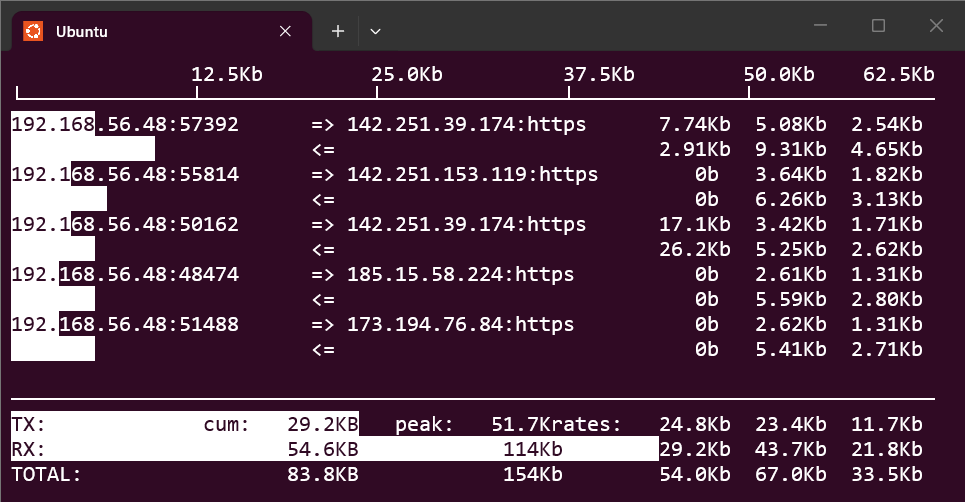

**05_iftop_api.png**

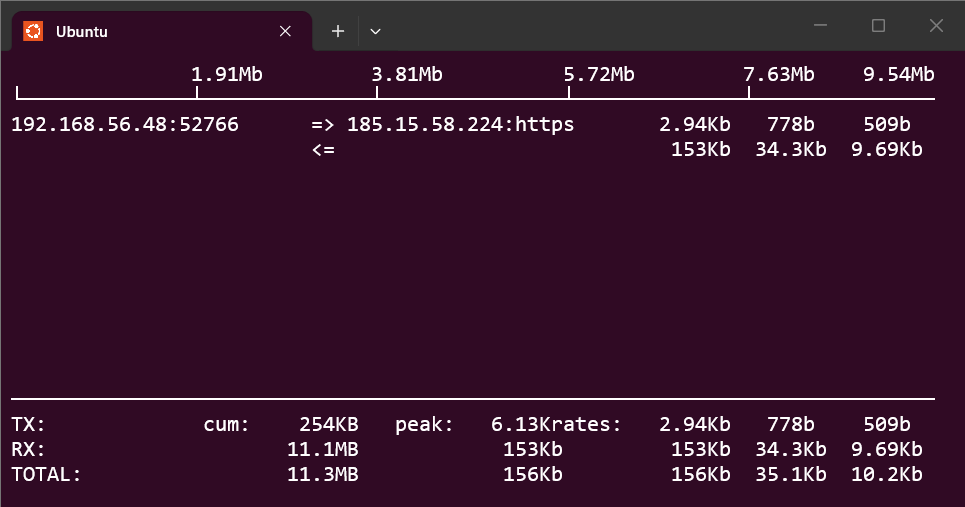

**06_nload_all.png**

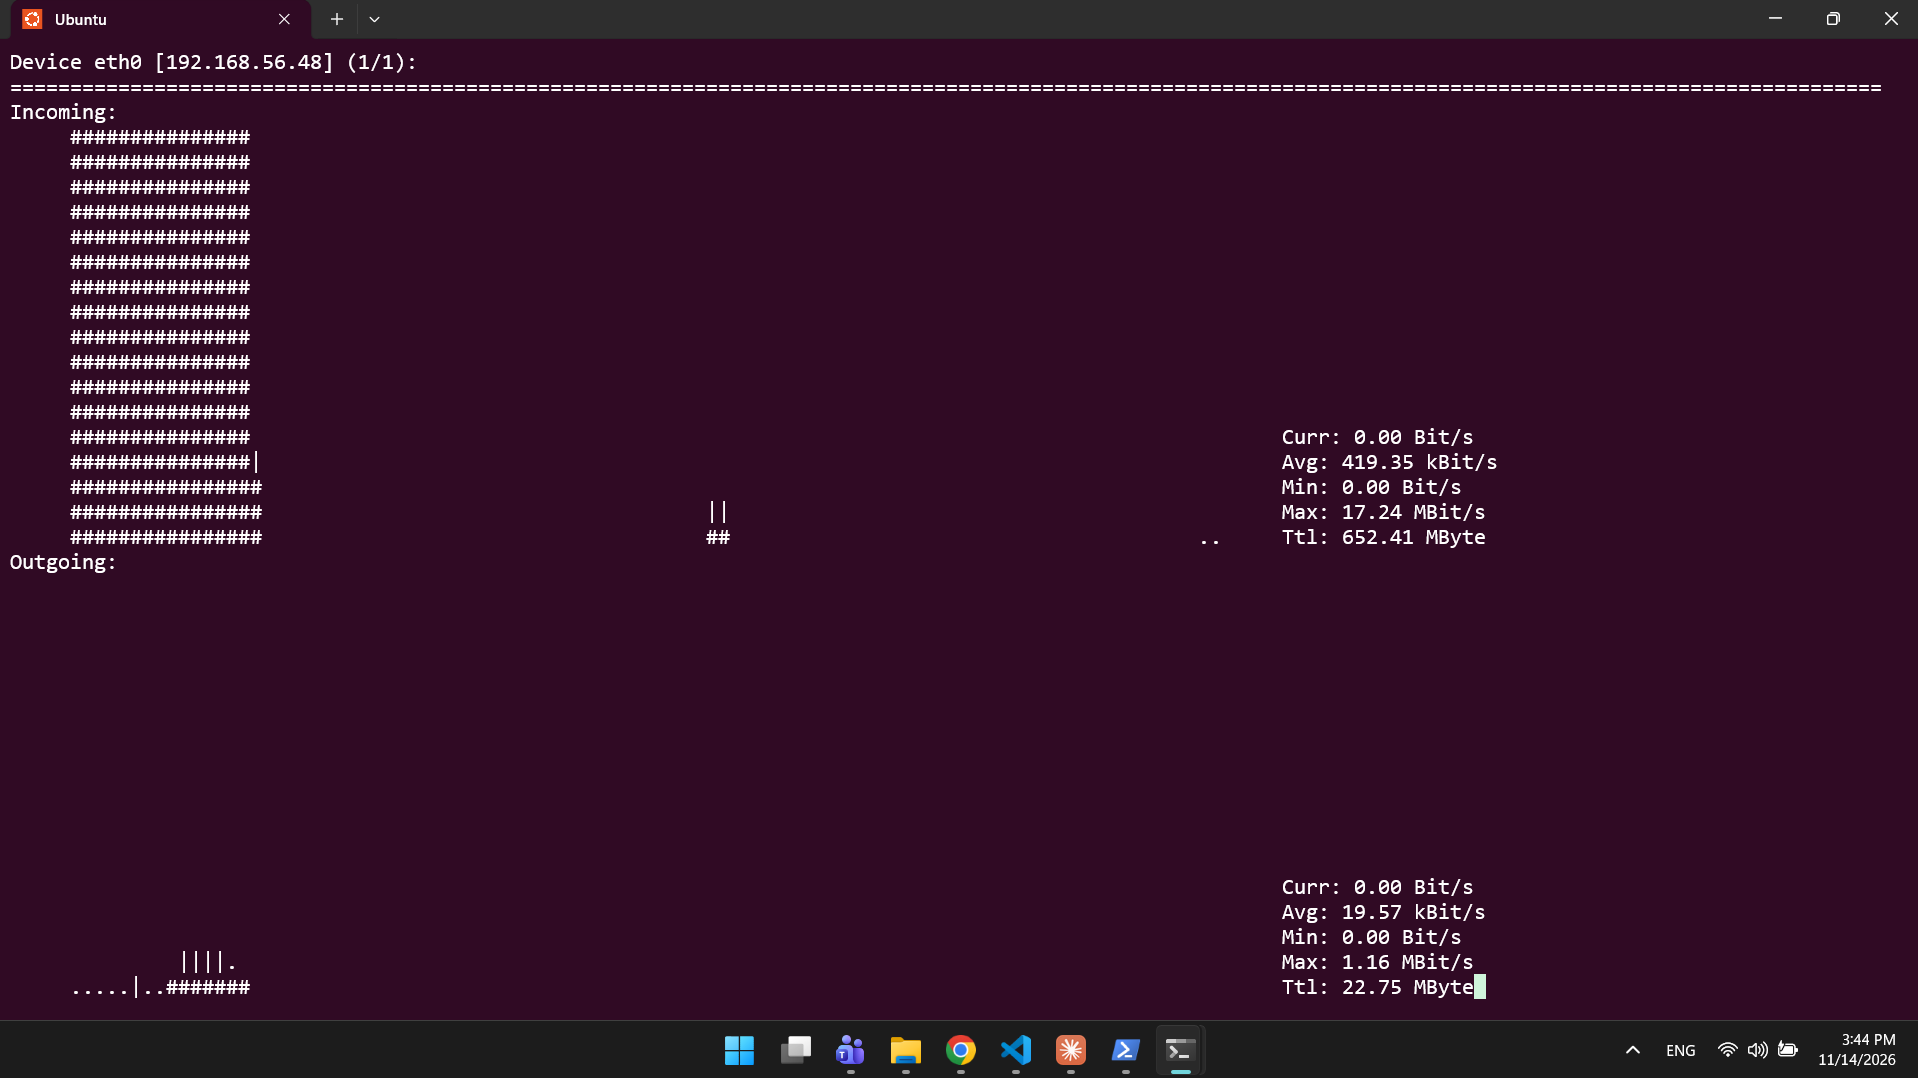

In [14]:
for f in ["04_iftop_selenium.png", "05_iftop_api.png", "06_nload_all.png"]:
    display(Markdown(f"**{f}**")); show(SHOT / f, 700)

### Wireshark

**09_ws_conversations.png** — Conversations (TCP) sorted by bytes

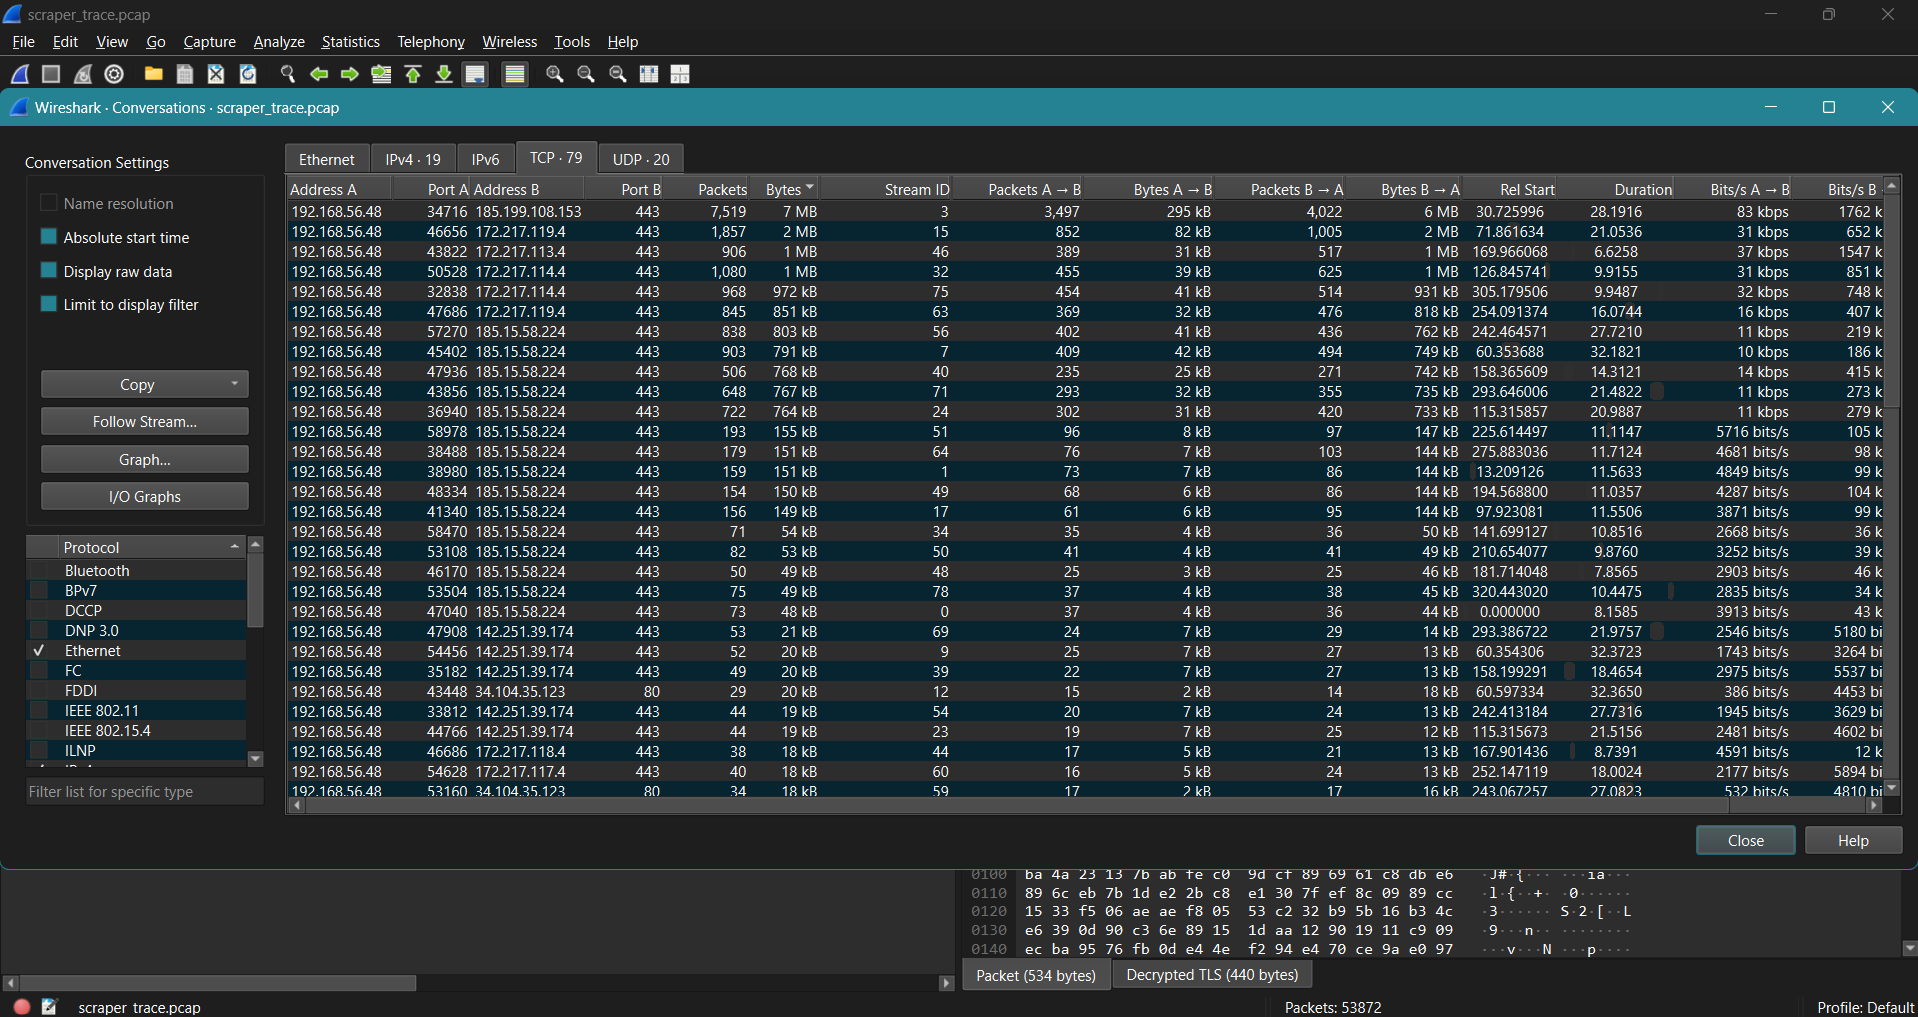

**10_ws_client_hello.png** — TLS ClientHello with the server name (SNI) in clear text

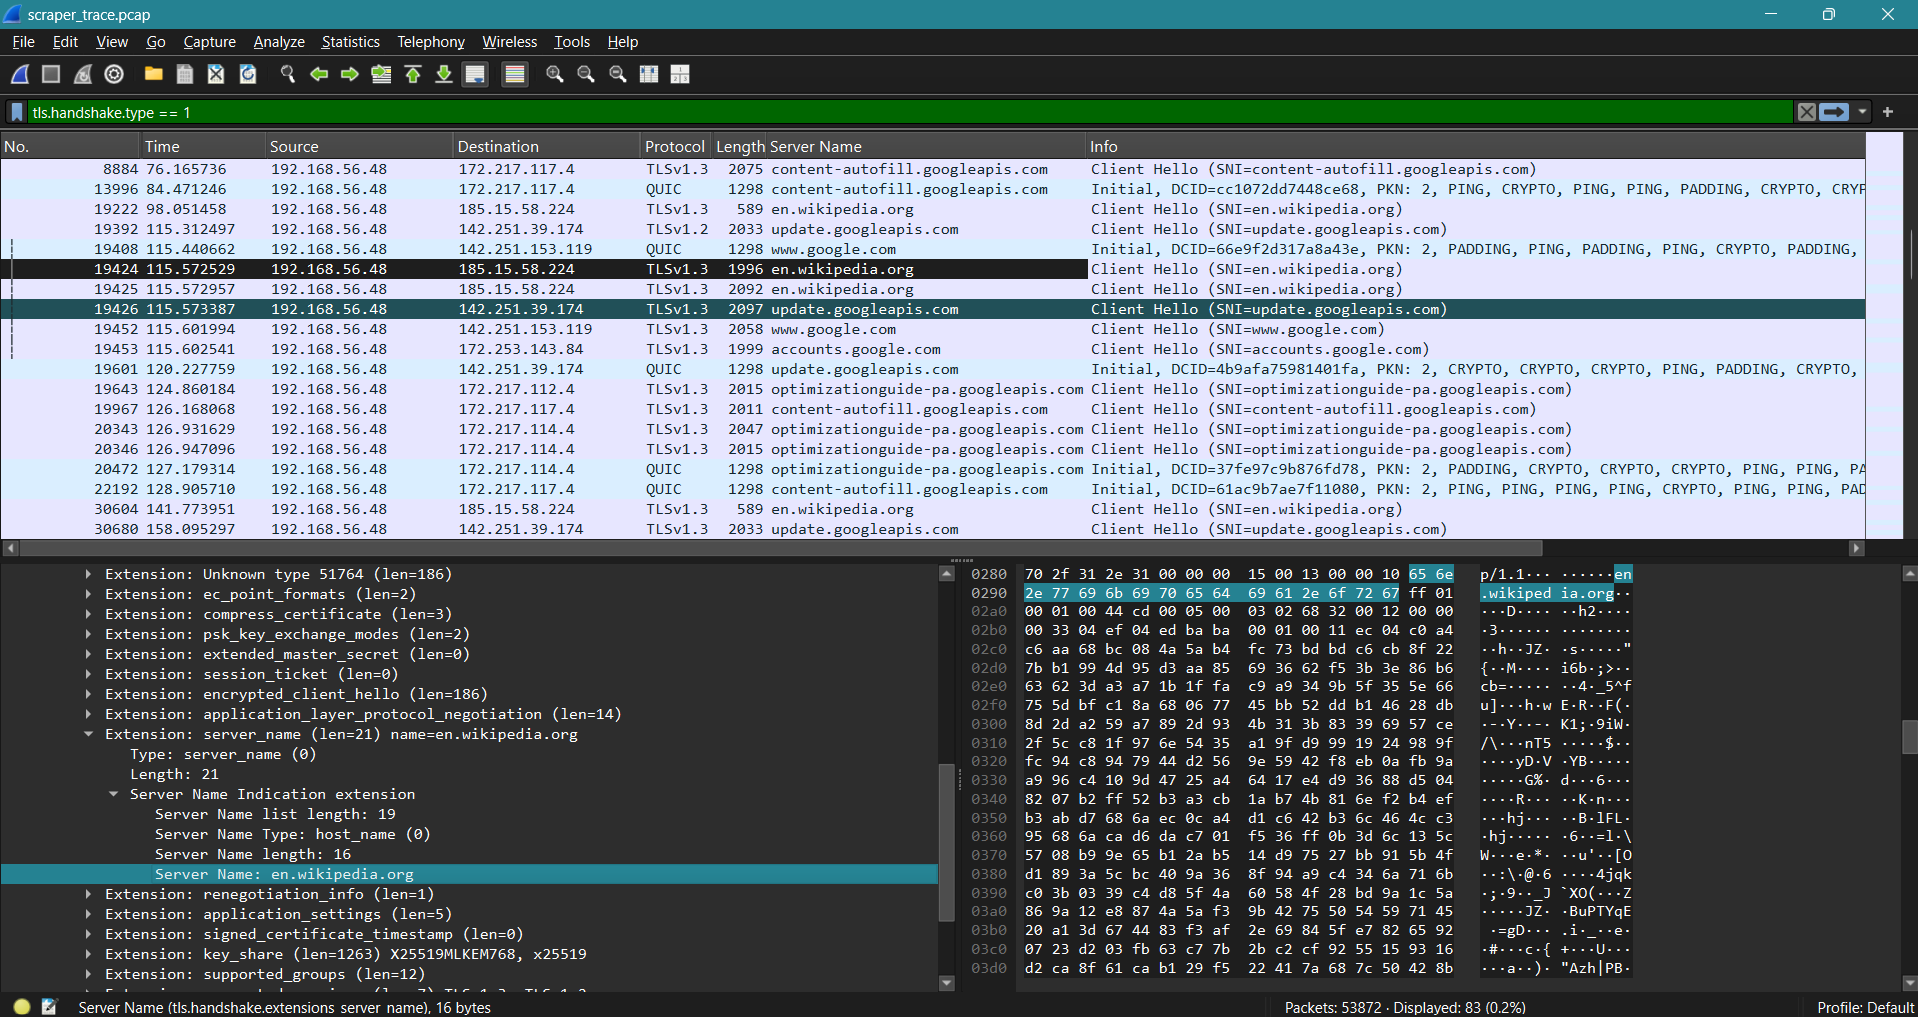

**11_ws_io_graph.png** — I/O graph: one burst per run

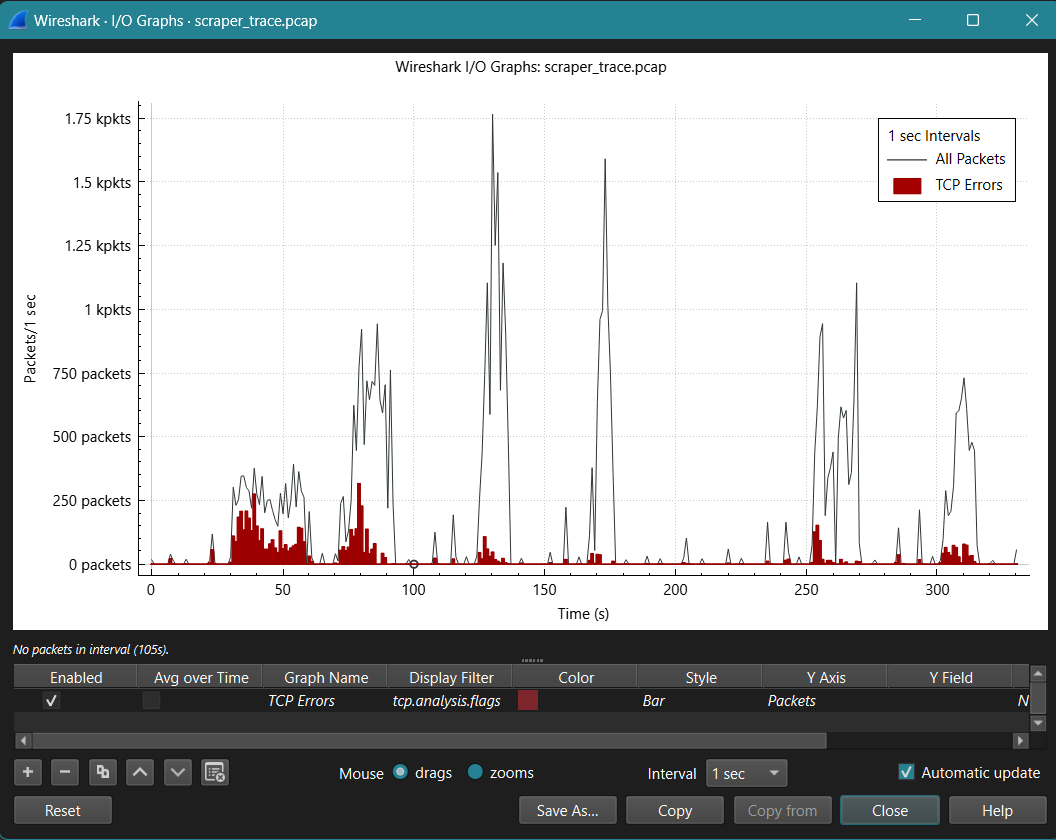

**12_ws_syn.png** — New TCP connections (SYN): 78

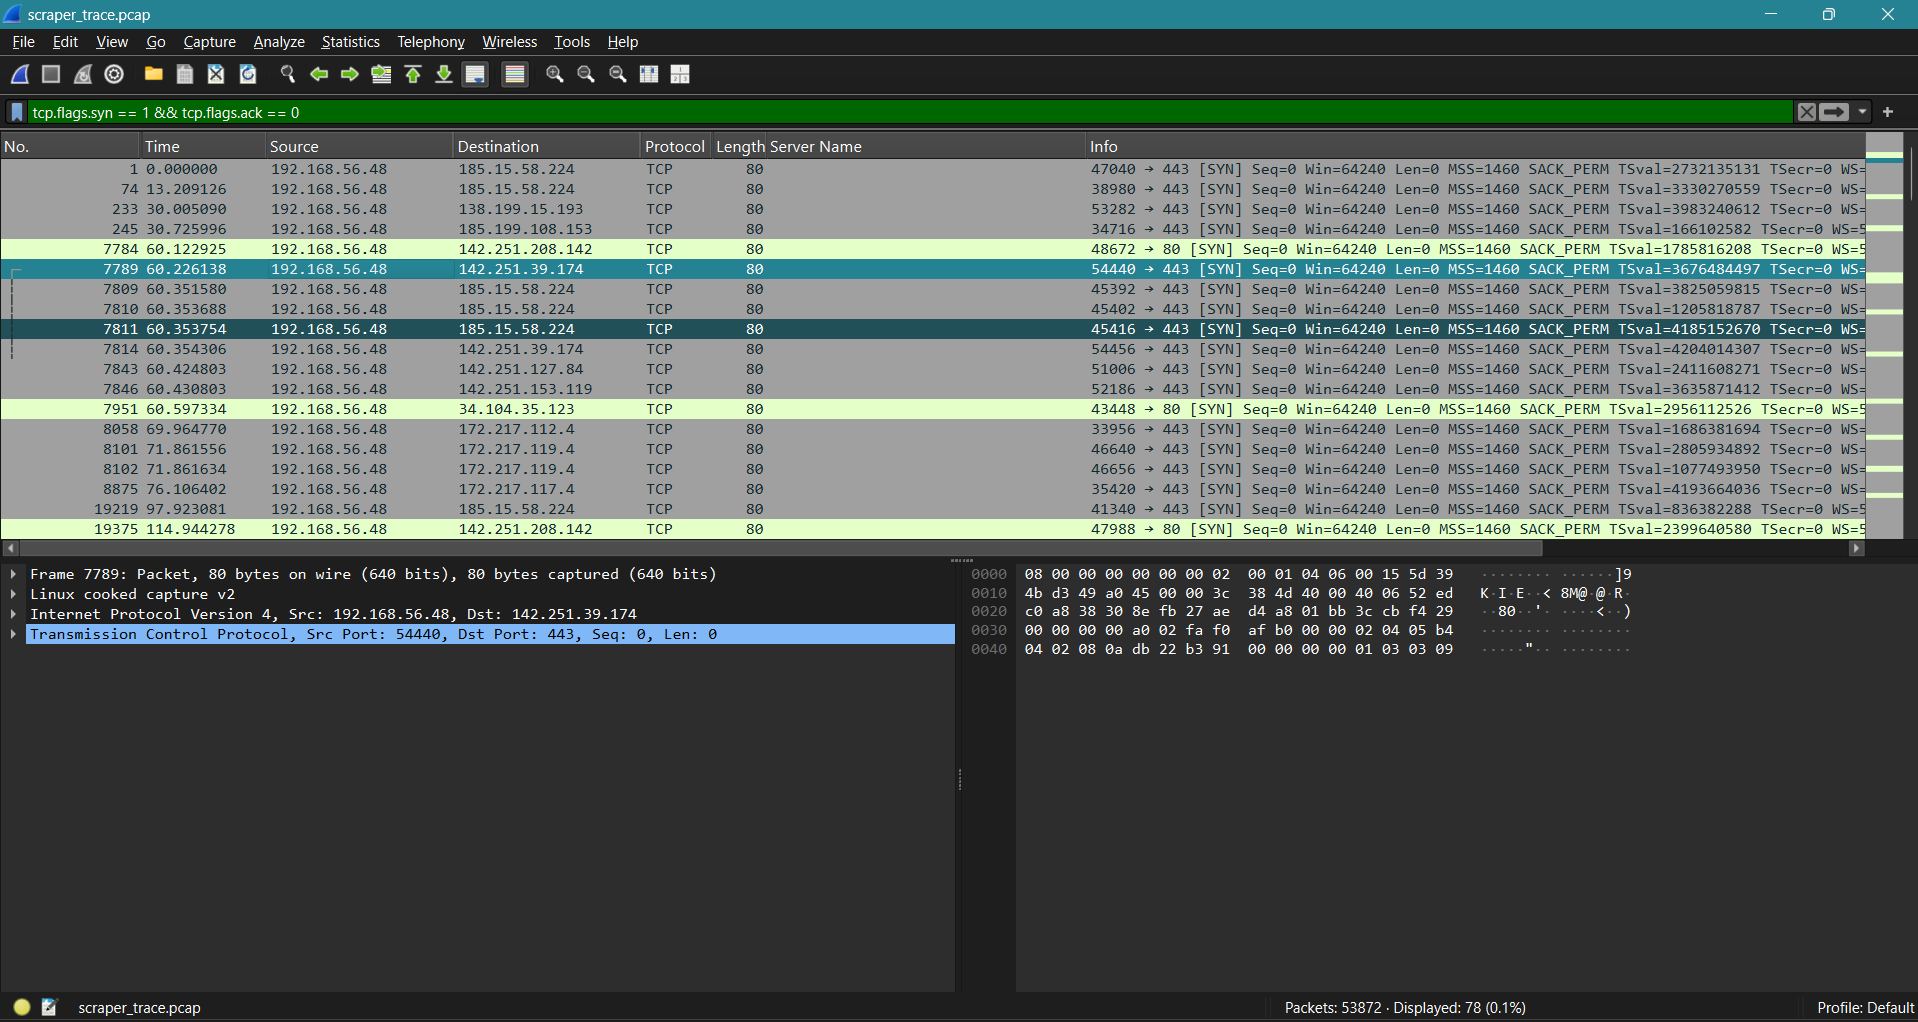

**13_ws_retrans.png** — tcp.analysis.retransmission: 1,662

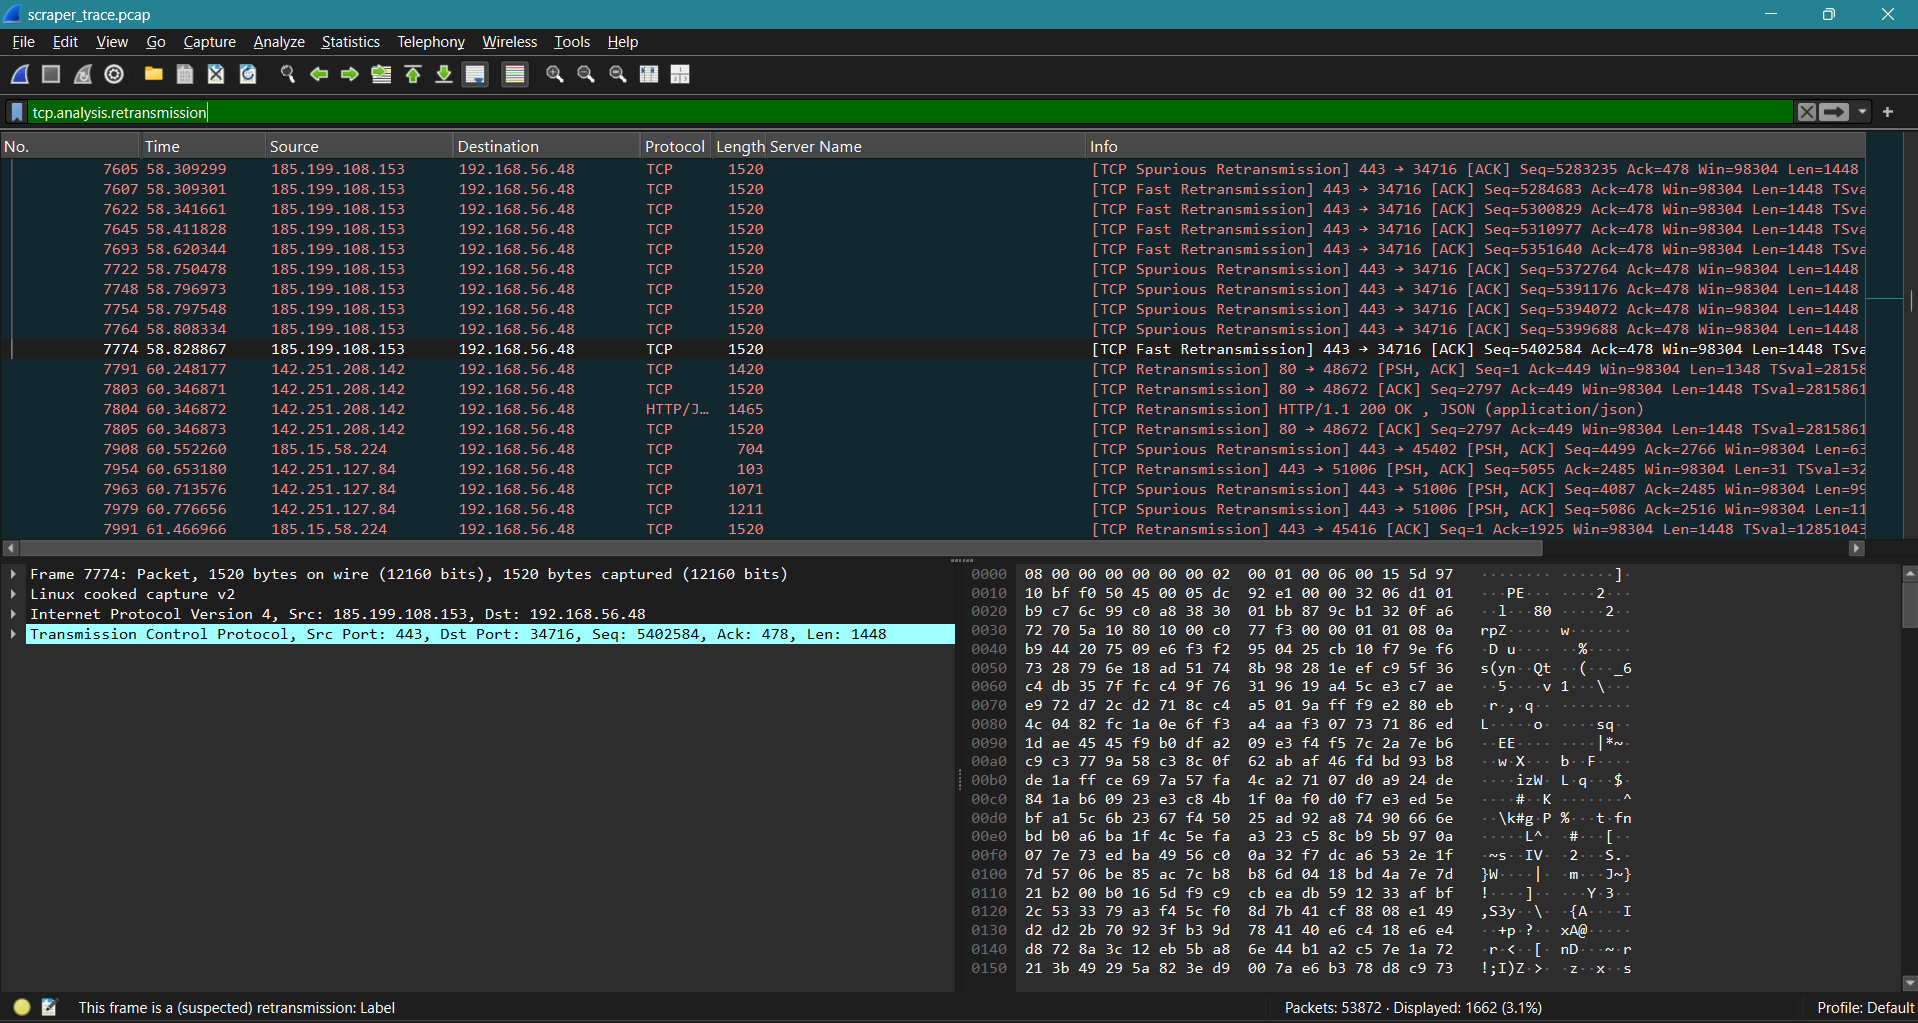

**14_ws_encrypted.png** — Without keys: encrypted Application Data

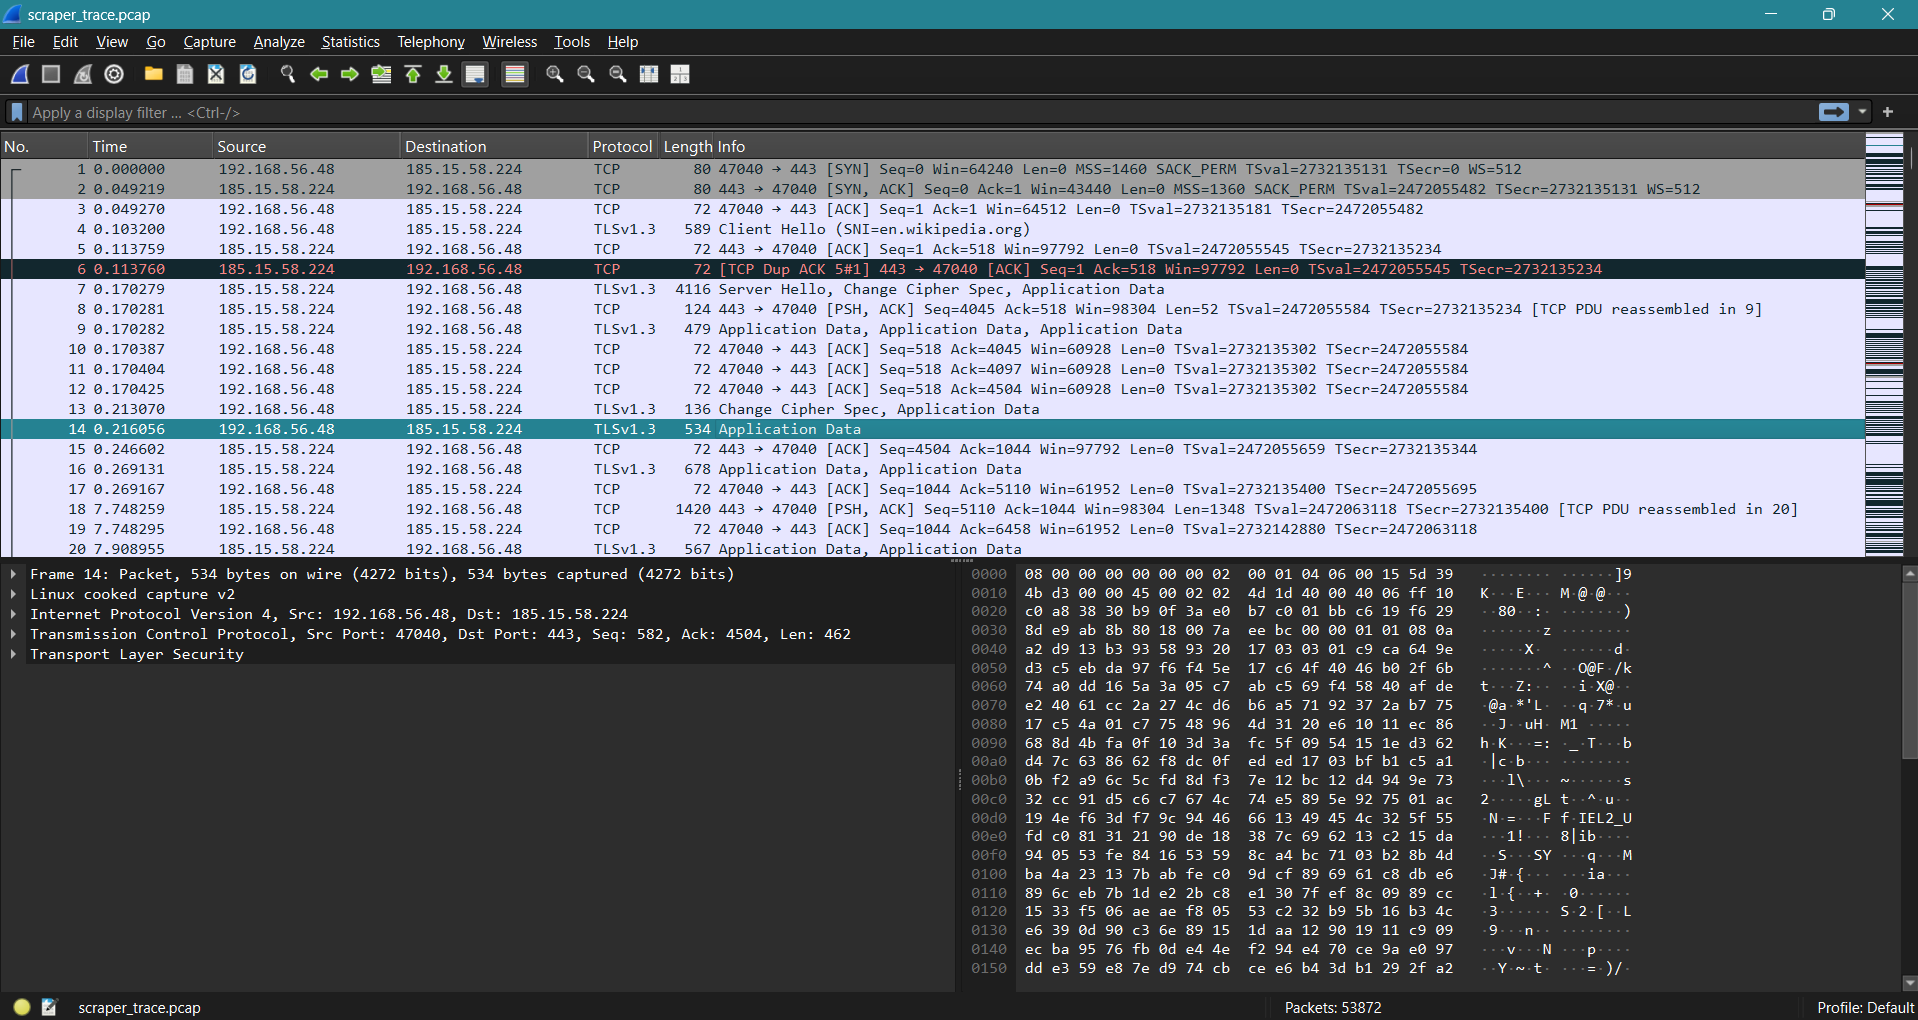

**15_ws_decrypted_http.png** — With SSLKEYLOGFILE: the real GET requests (API, BS4 HTTP/1.1, Selenium HTTP/2) and Chrome's own requests

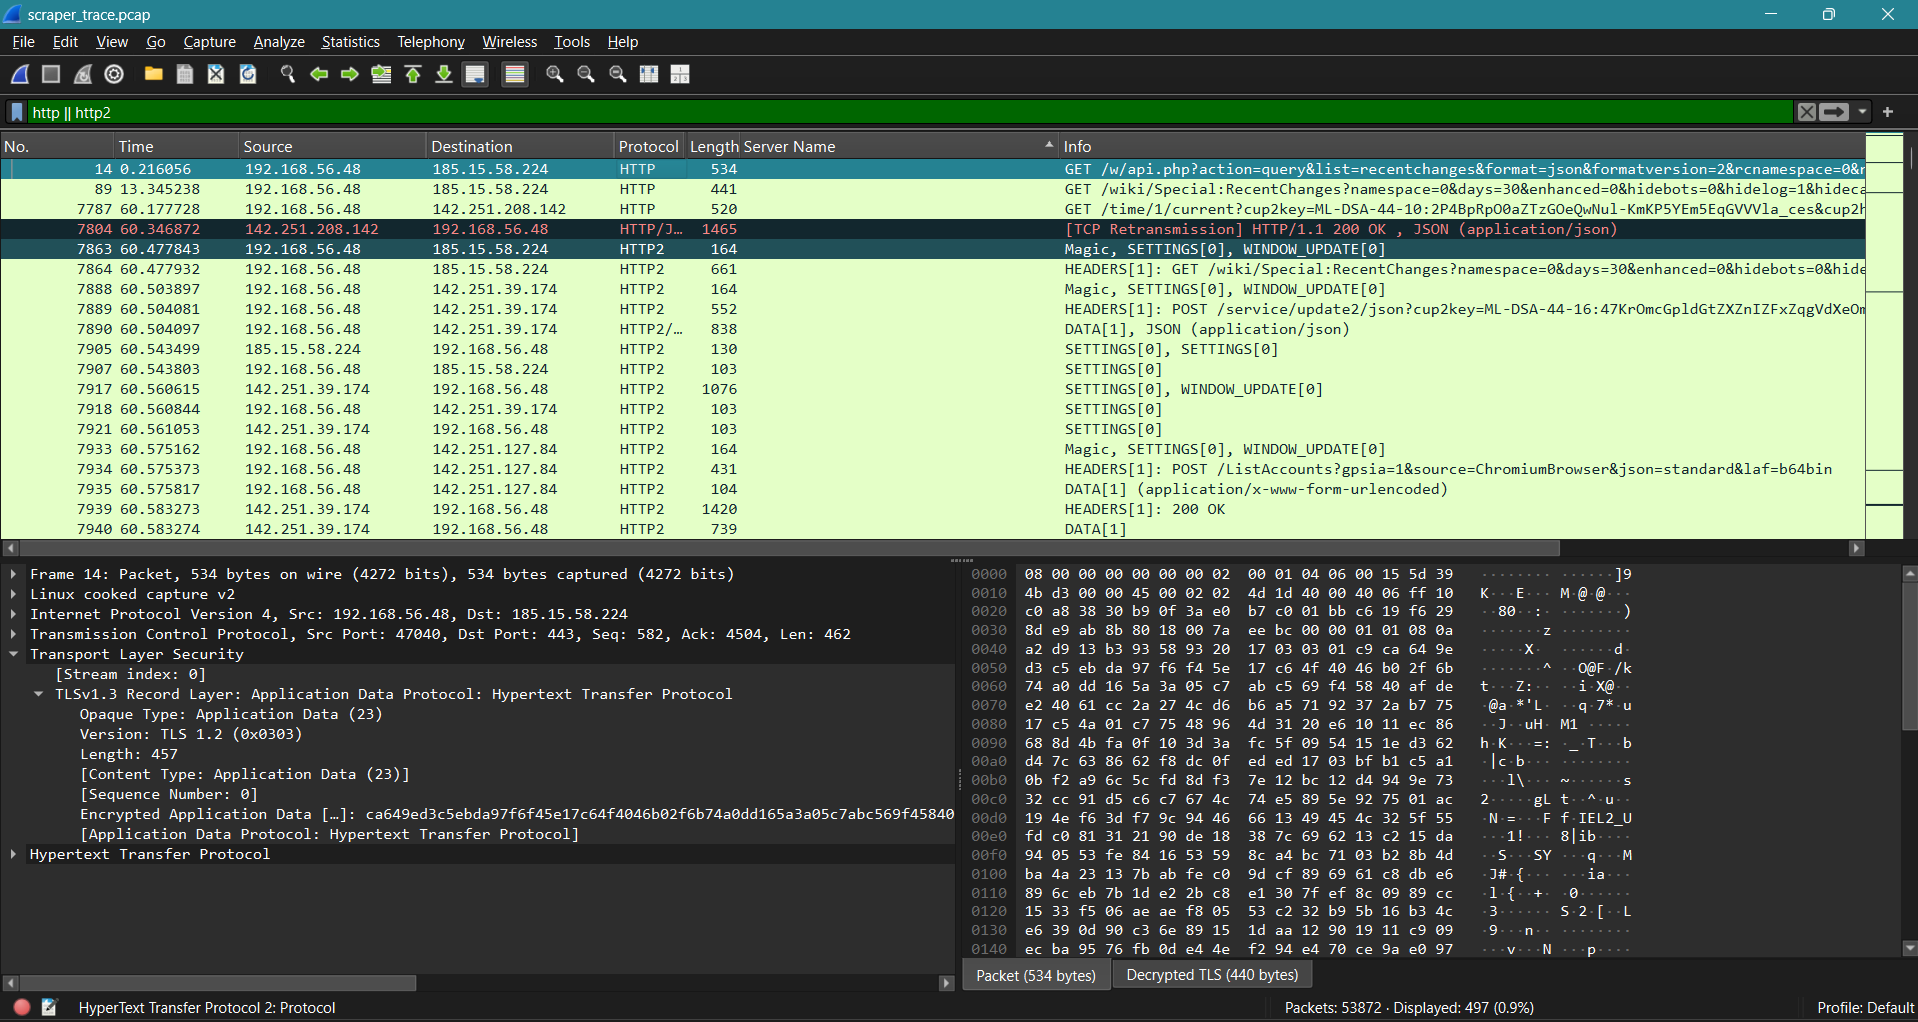

**16_ws_protocol_hierarchy.png** — Protocol hierarchy: QUIC = 63 % of all bytes

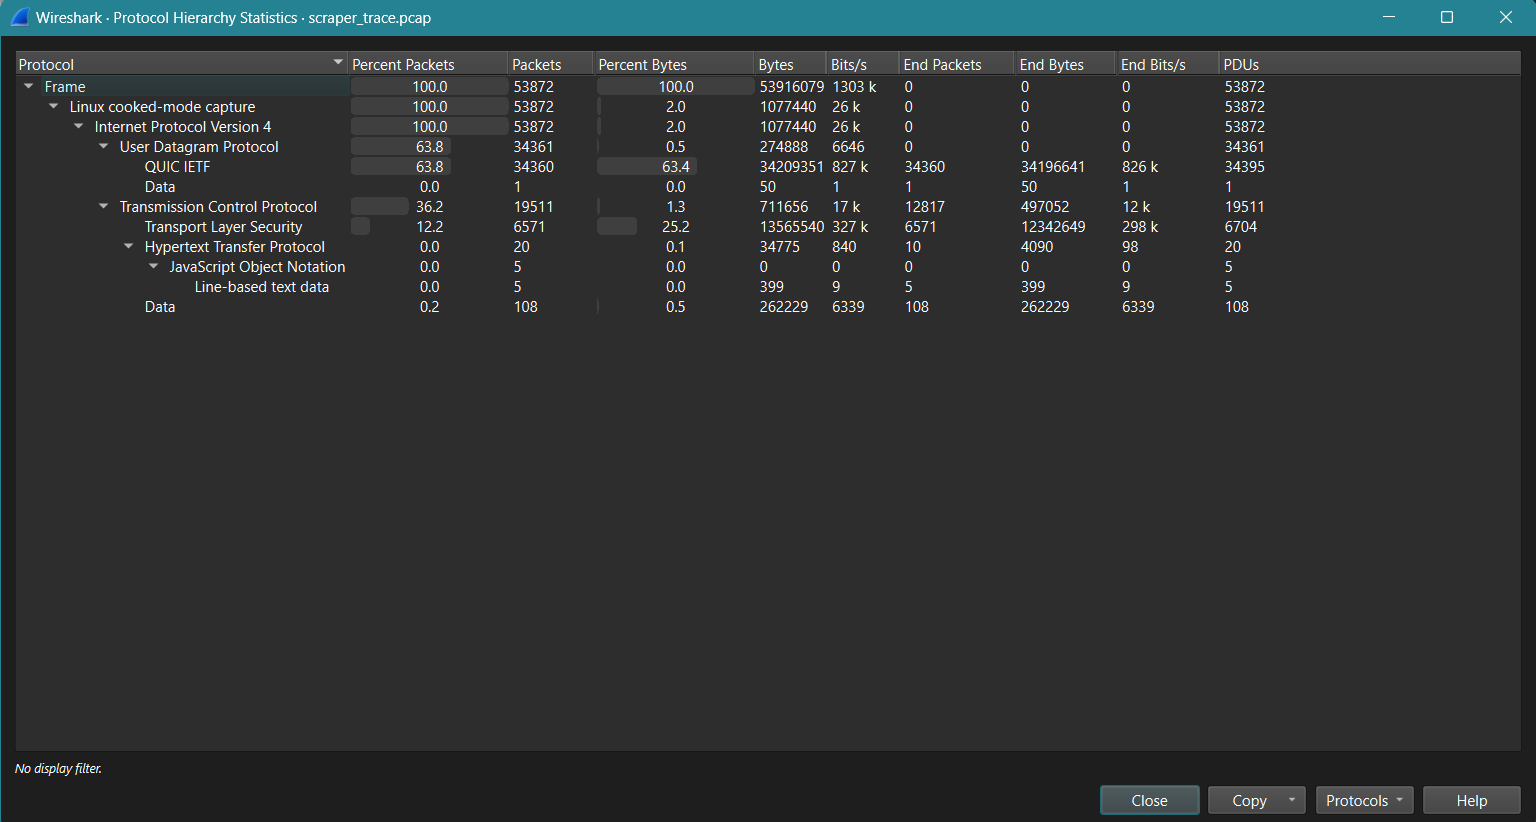

In [15]:
for f, cap in [("09_ws_conversations.png", "Conversations (TCP) sorted by bytes"),
               ("10_ws_client_hello.png", "TLS ClientHello with the server name (SNI) in clear text"),
               ("11_ws_io_graph.png", "I/O graph: one burst per run"),
               ("12_ws_syn.png", "New TCP connections (SYN): 78"),
               ("13_ws_retrans.png", "tcp.analysis.retransmission: 1,662"),
               ("14_ws_encrypted.png", "Without keys: encrypted Application Data"),
               ("15_ws_decrypted_http.png", "With SSLKEYLOGFILE: the real GET requests (API, BS4 HTTP/1.1, Selenium HTTP/2) and Chrome's own requests"),
               ("16_ws_protocol_hierarchy.png", "Protocol hierarchy: QUIC = 63 % of all bytes")]:
    display(Markdown(f"**{f}** — {cap}")); show(SHOT / f, 1000)

## 5. Resilience

### 5.1 Rate limiting and backoff (local mock server — provoking Wikimedia would be abusive)

,attempts,last_status,total_s,outcome
scenario,,,,
A: 429 + Retry-After 3 s (3×),4,200,9.006,success
"B: 503, no Retry-After (4×) → exponential",5,200,17.782,success
C: 429 forever → give up,6,429,5.010,gave up: giving up after 6 attempts: Transient...


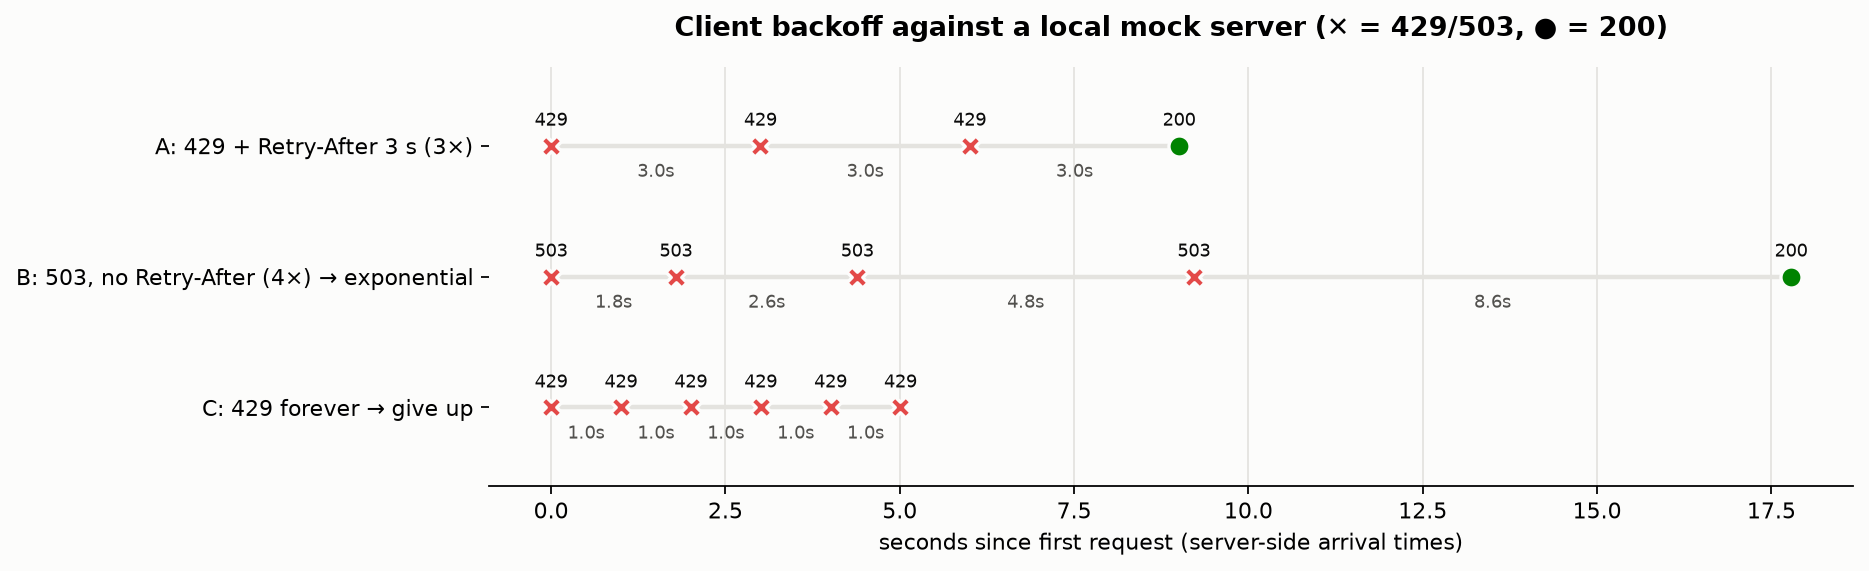

In [16]:
bd = pd.read_csv(M / "backoff_demo.csv")
display(bd.groupby("scenario").agg(attempts=("attempt", "size"), last_status=("status", "last"),
                                   total_s=("t_s", "max"), outcome=("outcome", "first")))
show(FIG / "backoff_demo.png", 1000)

In all 15 benchmark runs and 171 dataset requests against Wikipedia: **0 HTTP 429, 0 maxlag errors, 0 retries.**

### 5.2 Bounded multithreading: 1 vs 4 threads under a shared 1 request/s limit

wall_s       edits_per_s        avg_latency_ms         min_gap_between_starts_s      http_429     
          mean   std        mean    std           mean     std                     mean  std     mean  std
workers                                                                                                   
1        34.56  1.86       173.9   9.33         2563.7  245.37                      1.0  0.0      0.0  0.0
4        18.65  1.64       322.9  28.43         2741.2  229.95                      1.0  0.0      0.0  0.0

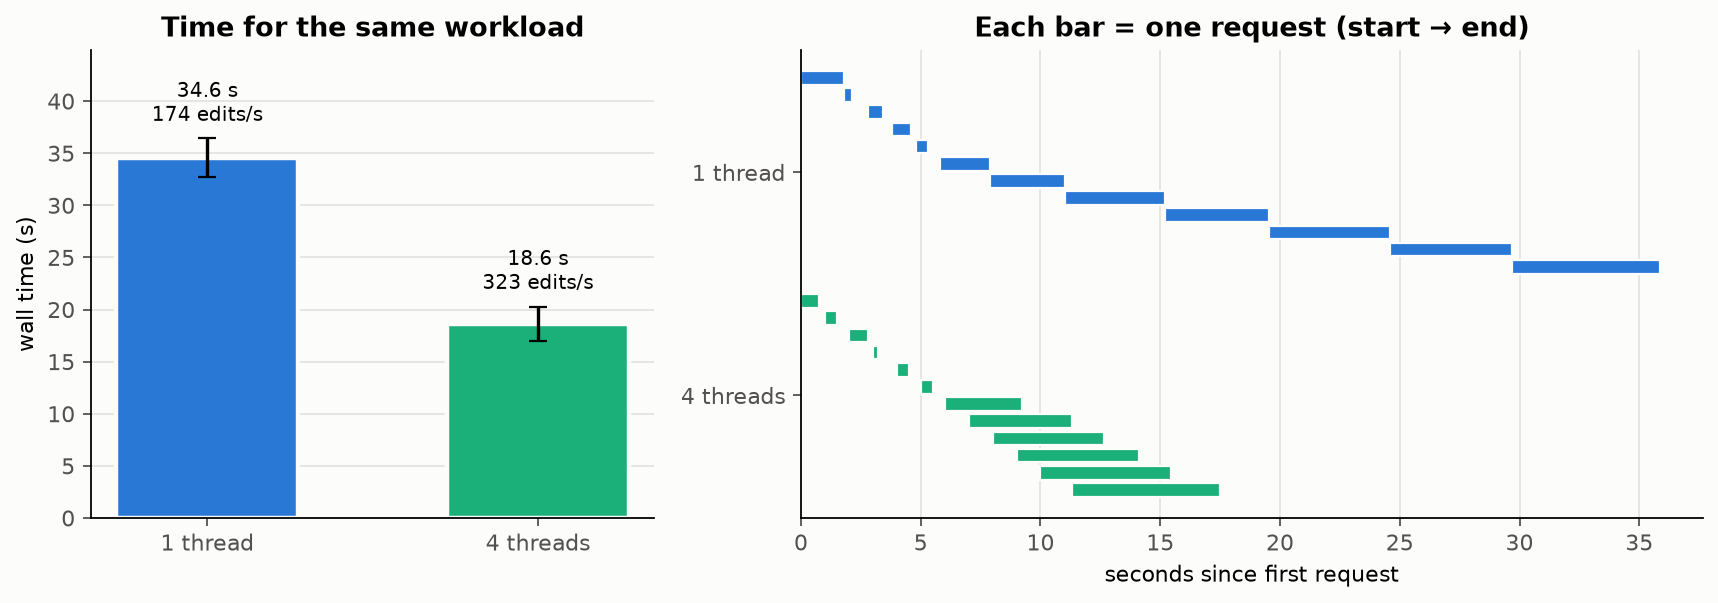

In [17]:
th = pd.read_csv(M / "threads_api.csv")
display(th.groupby("workers")[["wall_s", "edits_per_s", "avg_latency_ms", "min_gap_between_starts_s", "http_429"]]
          .agg(["mean", "std"]).round(2))
show(FIG / "threads_api.png", 1000)

4 threads → 1.86× throughput, not 4×: threads overlap the *waiting*, the shared limiter still spaces request *starts* ≥ 1 s apart. Per-request latency did not rise (the server was not stressed); `ss` saw at most 4 parallel connections.

### 5.3 Firewall: outbound HTTPS blocked with ufw for 60 s

In [18]:
rs = pd.read_csv(M / "resilience_summary.csv").set_index("run_id")
rs[["method", "mode", "block_s", "ok", "failed", "failed_touching_block", "s_per_failed_attempt",
    "recovery_s_after_restore", "read_timeouts_outside_block"]]

,method,mode,block_s,ok,failed,failed_touching_block,s_per_failed_attempt,recovery_s_after_restore,read_timeouts_outside_block
run_id,,,,,,,,,
fw2_deny_api_1732,api,deny,61.8,10,2,2,5.03,10.3,0
fw2_reject_api_1732,api,reject,62.0,9,3,3,0.02,17.5,0
fw2_deny_bs4_1732,bs4,deny,62.1,9,2,2,9.27,14.9,0
fw2_deny_selenium_1732,selenium,deny,62.0,9,0,0,NaN,16.9,0


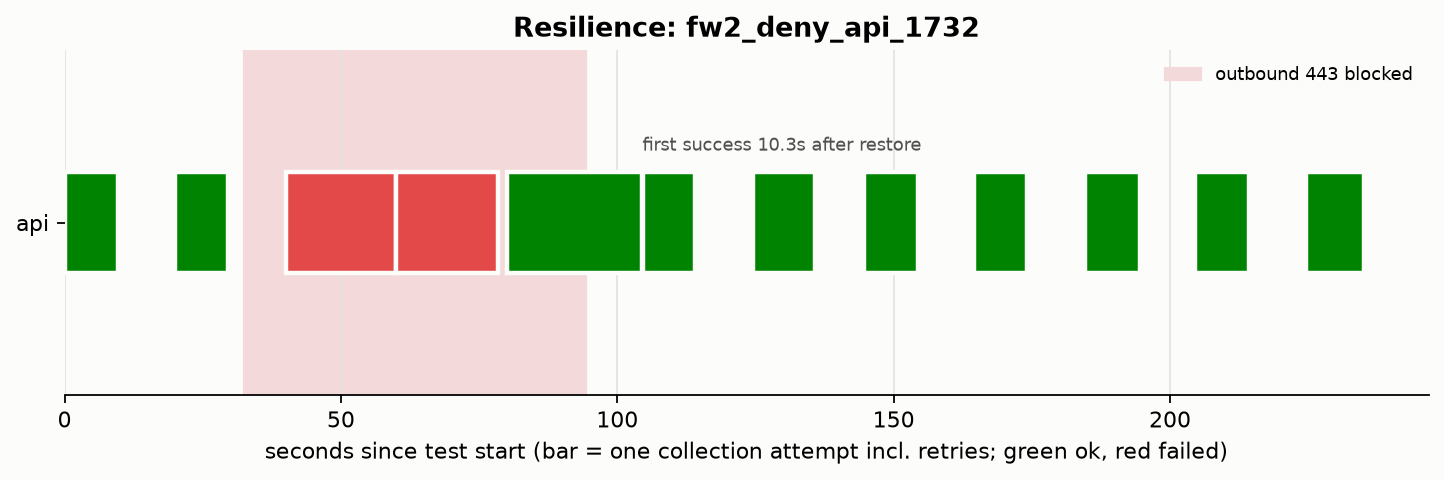

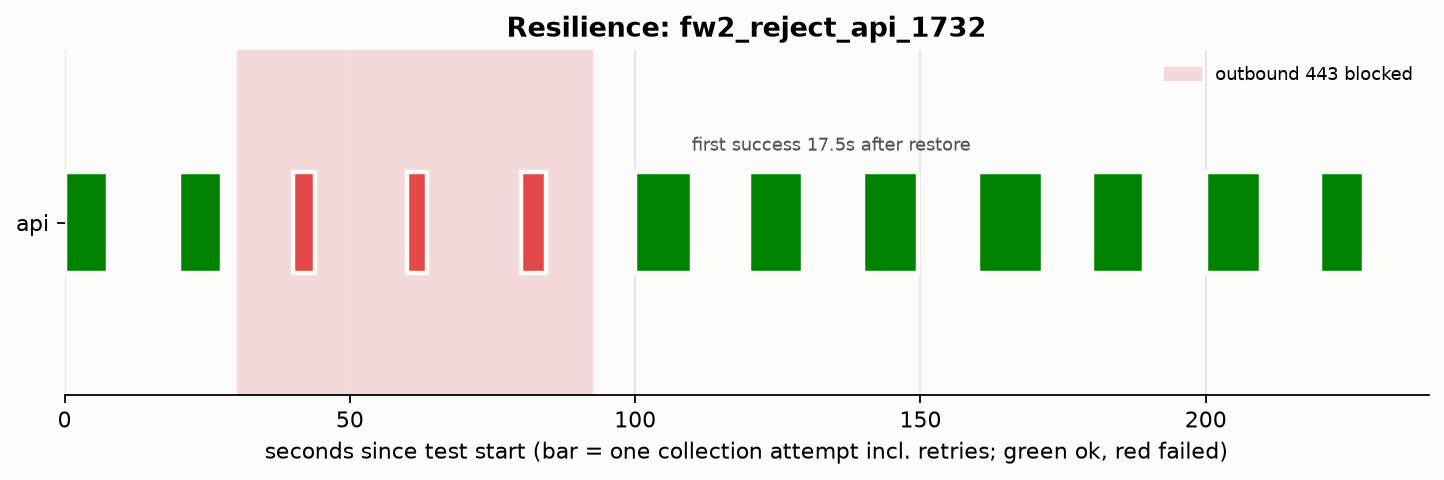

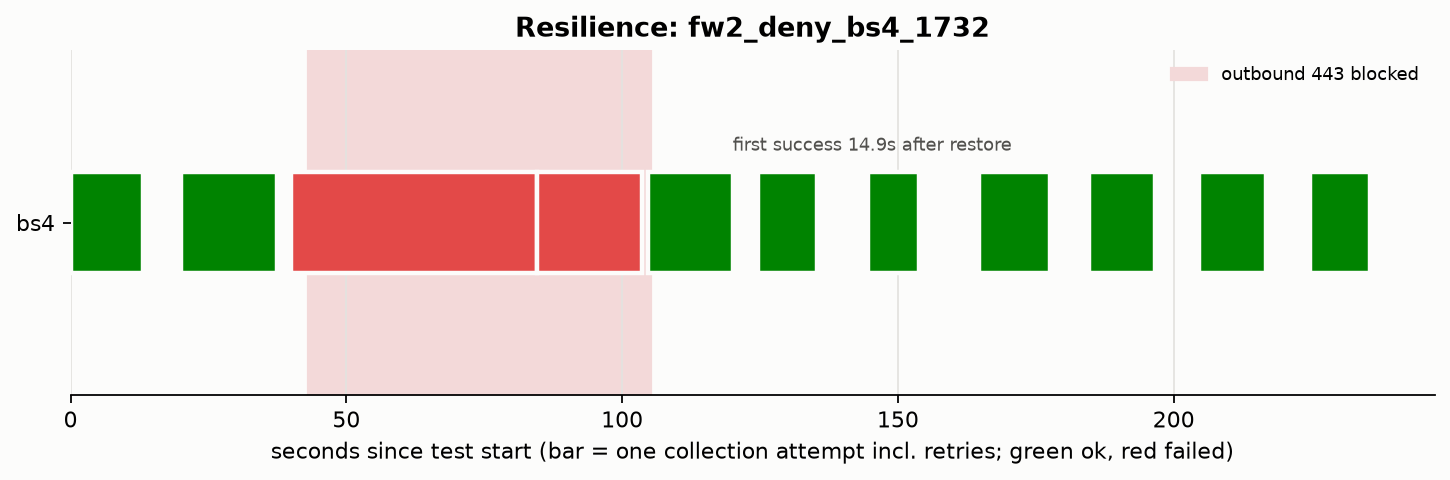

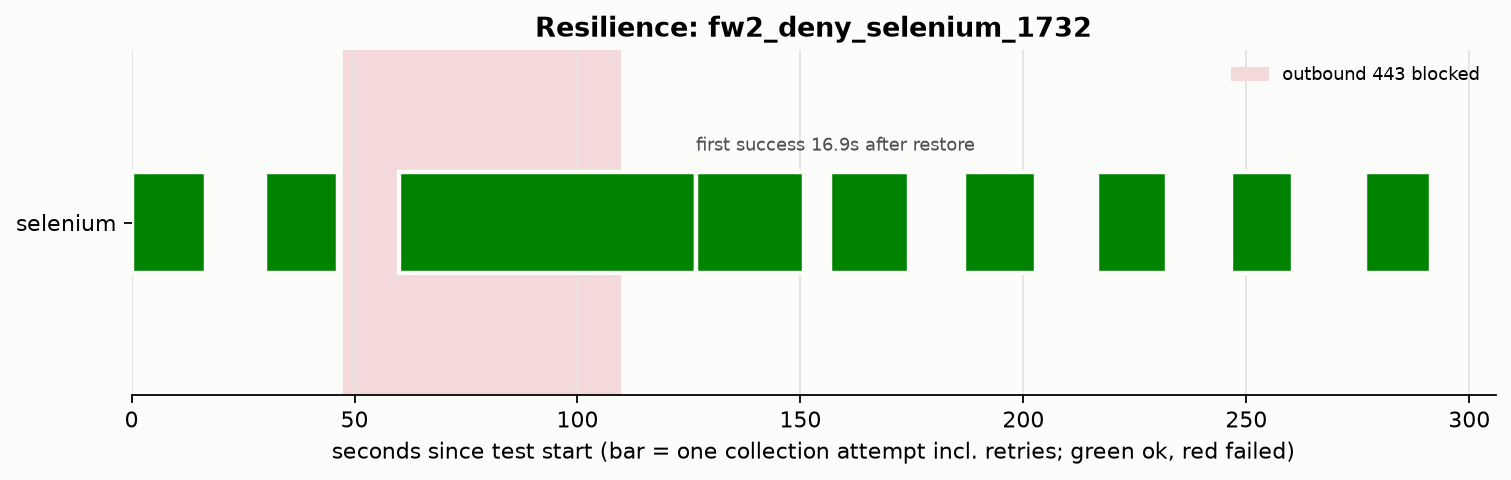

In [19]:
for r in rs.index:
    show(FIG / f"resilience_{r}.png", 1000)

**17_ufw_blocked.png**

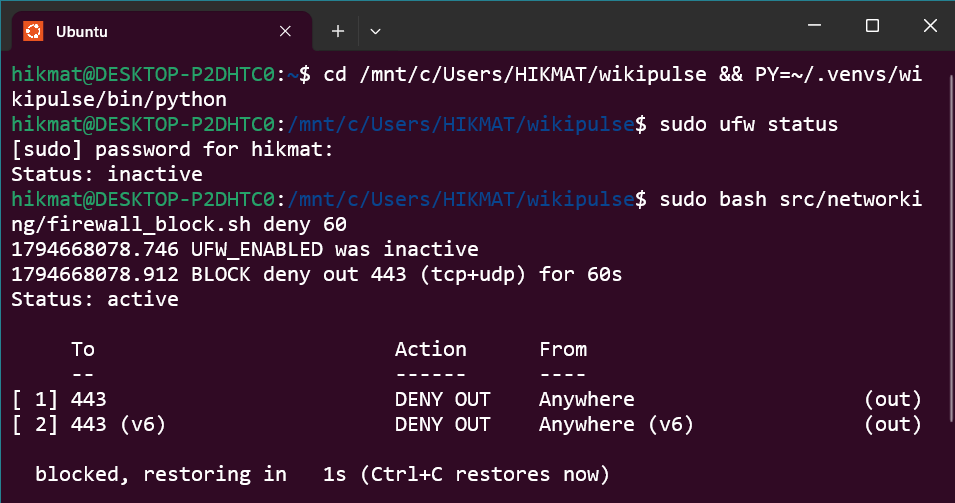

**18_resilience_failing.png**

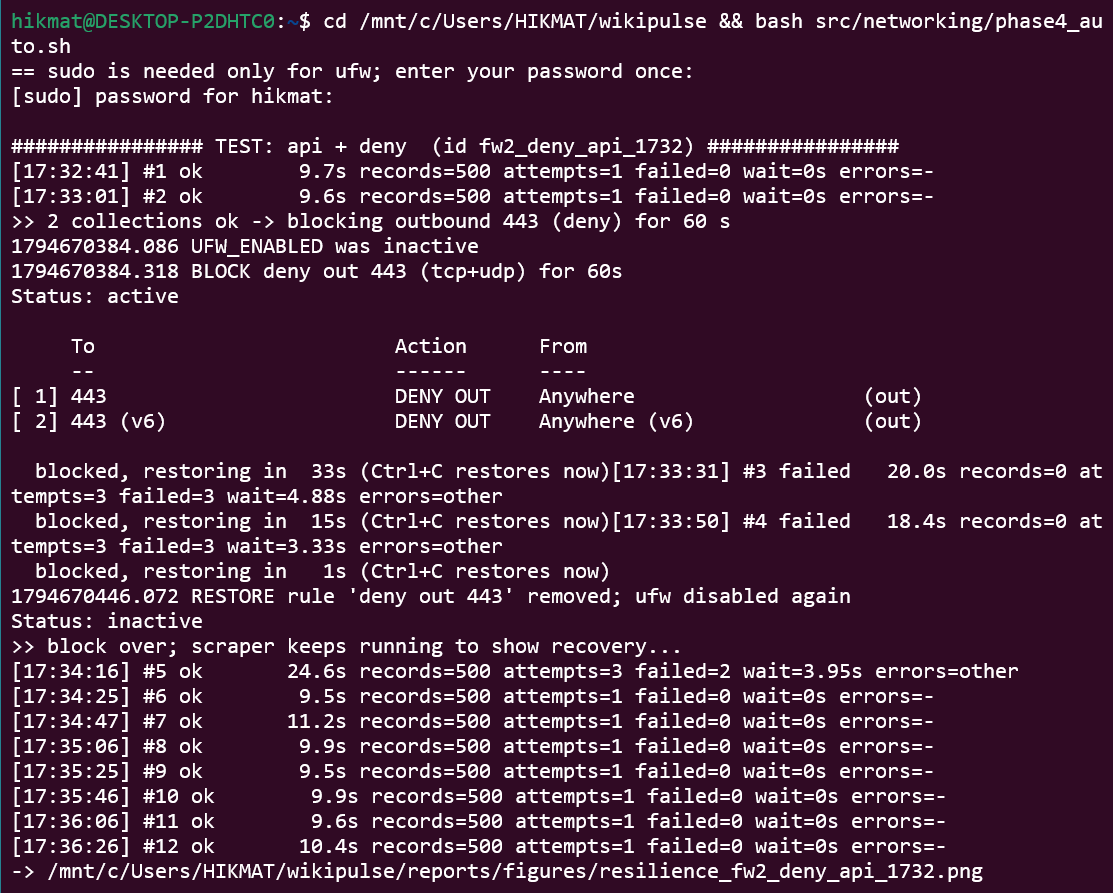

**21_resilience_reject.png**

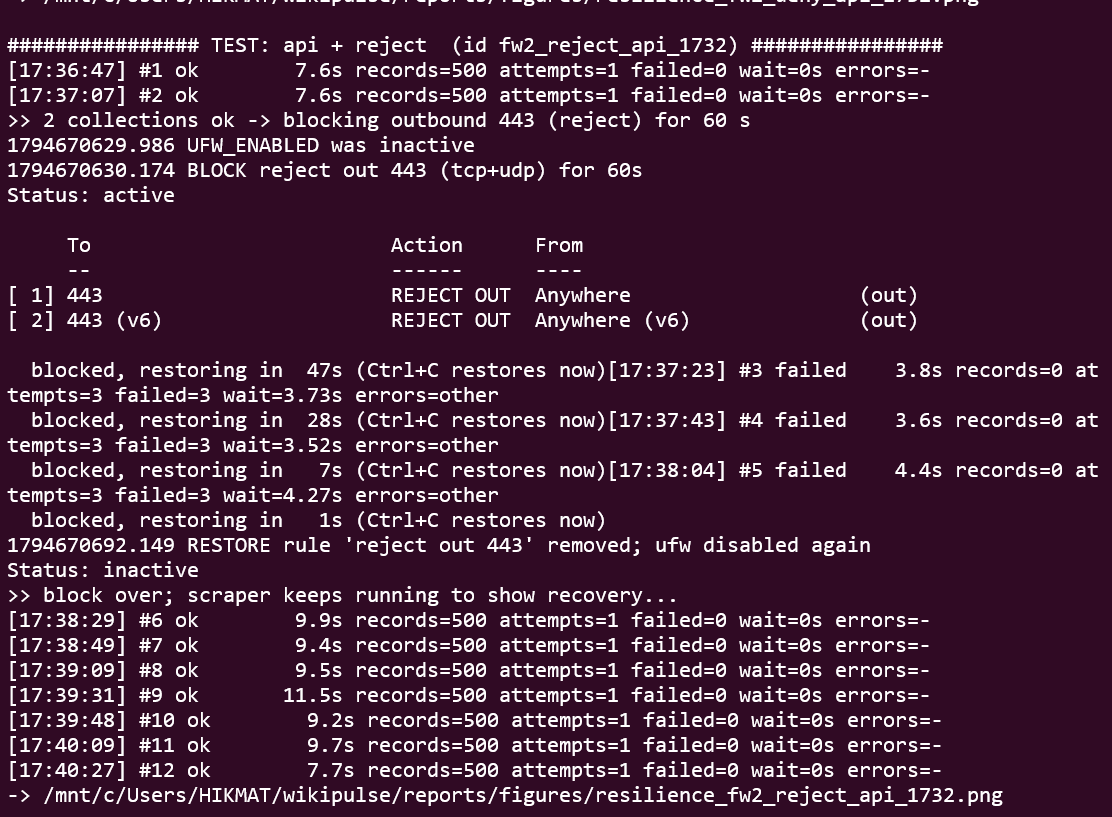

**22_resilience_selenium.png**

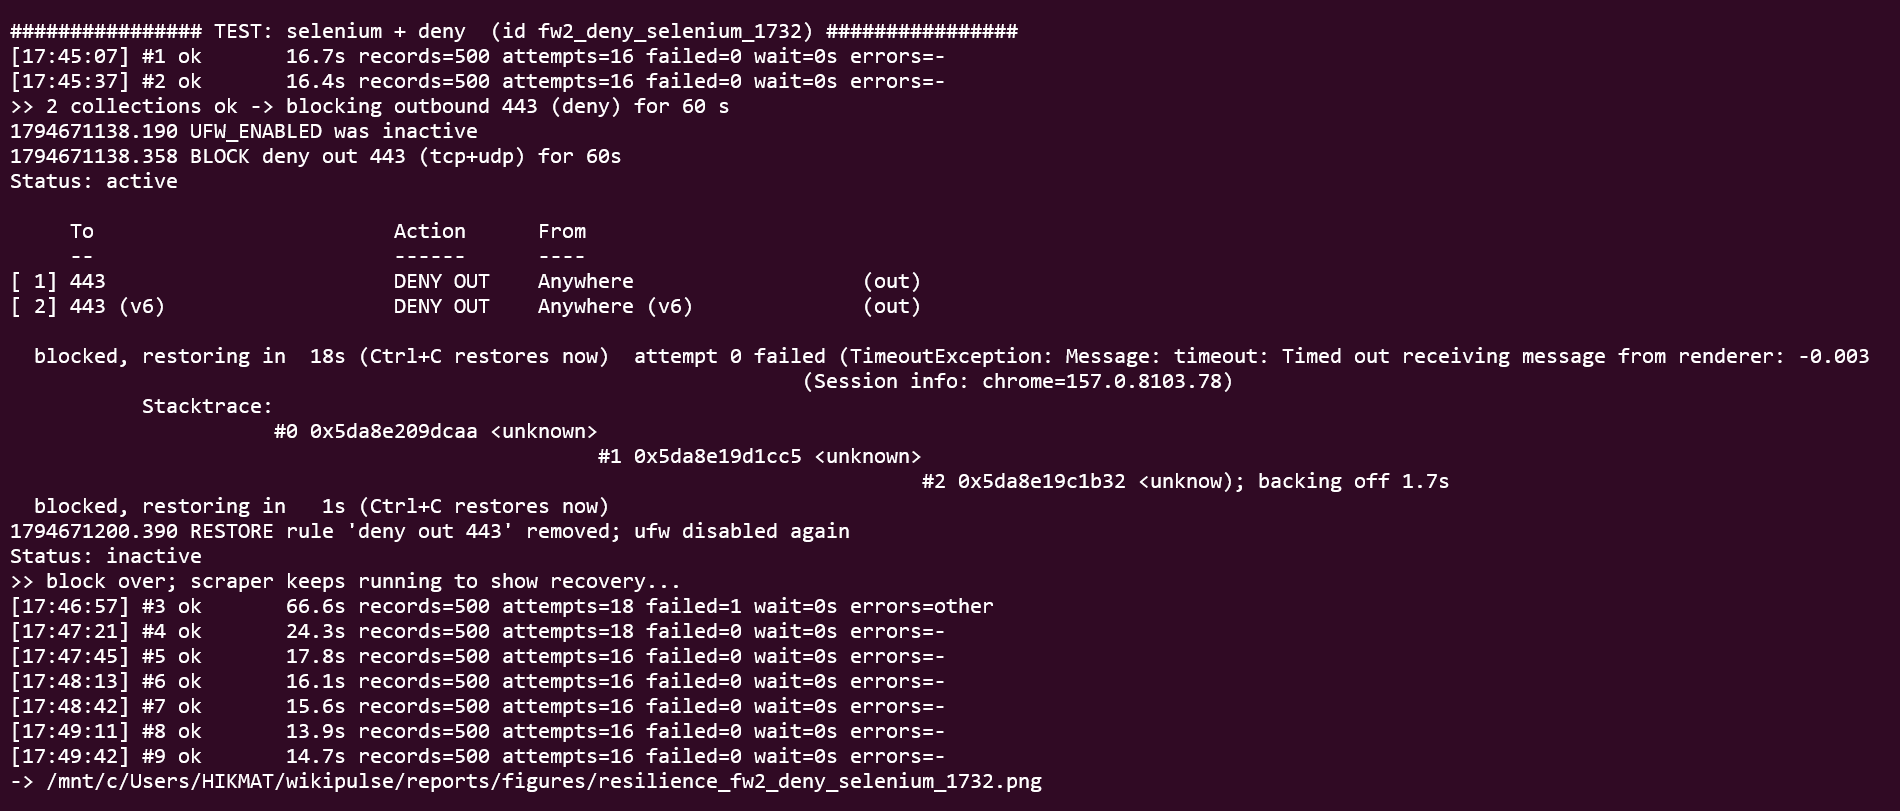

**19_ufw_restored.png**

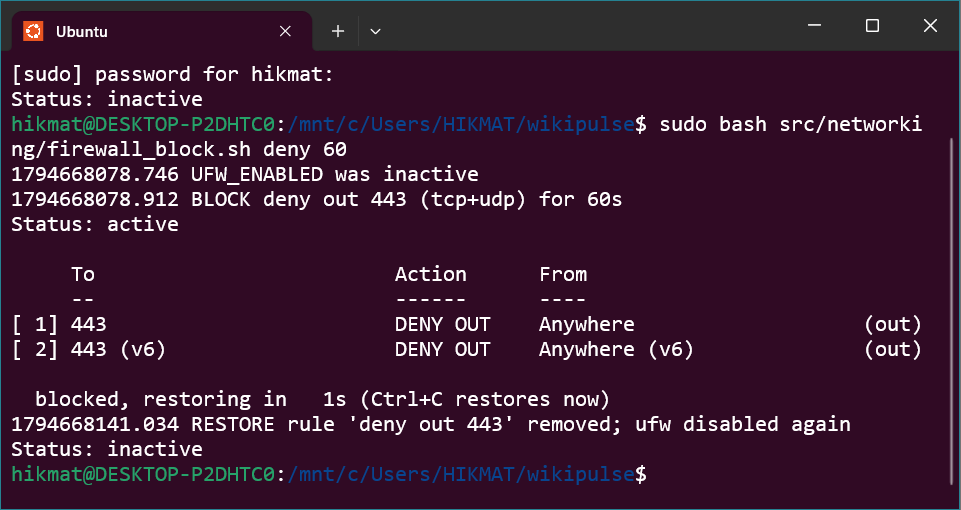

**20_resilience_summary.png**

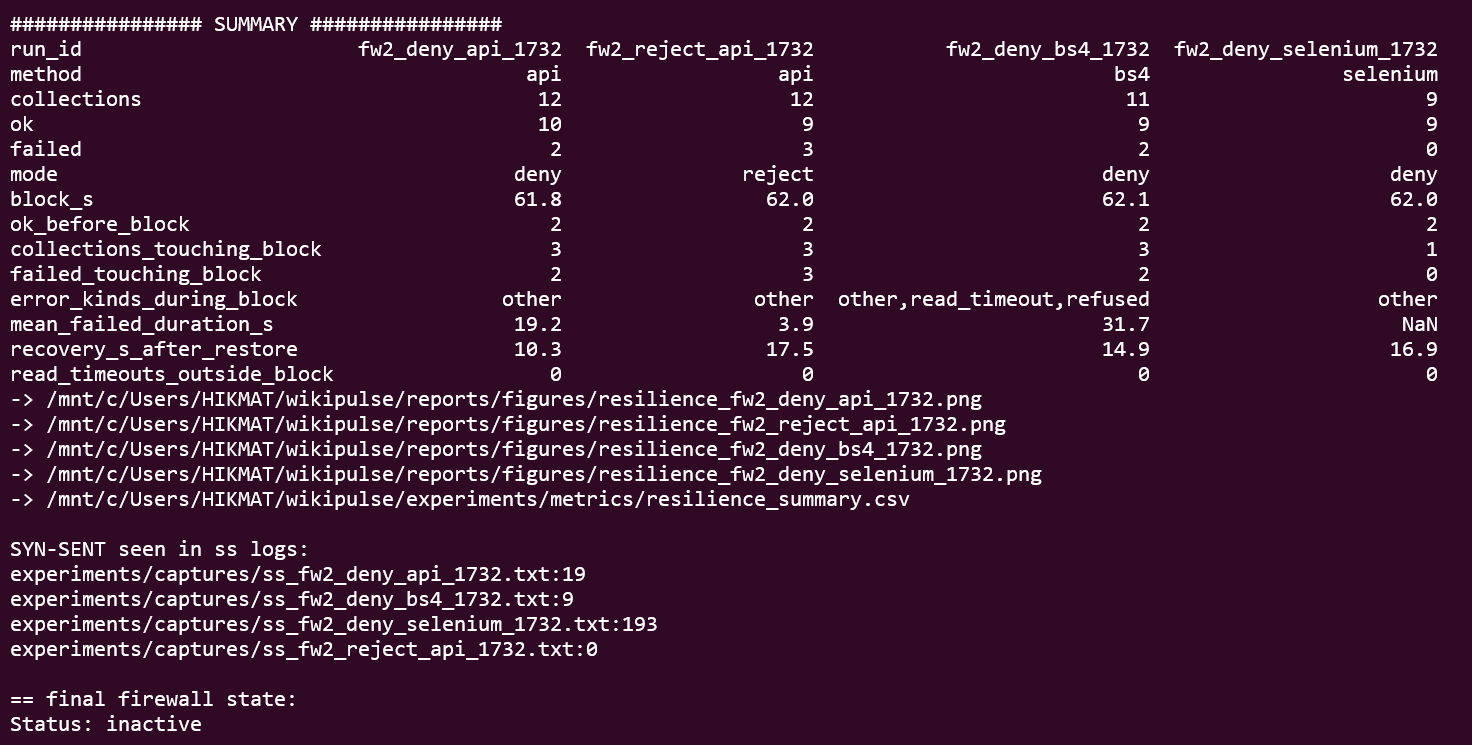

In [20]:
for f in ["17_ufw_blocked.png", "18_resilience_failing.png", "21_resilience_reject.png",
          "22_resilience_selenium.png", "19_ufw_restored.png", "20_resilience_summary.png"]:
    display(Markdown(f"**{f}**")); show(SHOT / f, 800)

- **deny** (silent drop): each failed attempt costs the full connect timeout (**5.03 s**); `ss` shows sockets stuck in
  `SYN-SENT` (19 snapshots for the API run).
- **reject** (active refusal): each attempt fails in **~0.02 s** — the client learns immediately.
- All three methods **recovered on their next collection** (10–17 s after the restore); Selenium's page load timed out,
  retried, and finished after the restore.
- *Honesty note:* a first attempt (archived in `experiments/metrics/phase4_attempt1/`) was invalid — our read timeout (8 s)
  was shorter than the API's own response time (~9 s), so slow-server timeouts looked like firewall failures. Separating
  connect and read timeouts fixed it (0 read timeouts outside the blocks in attempt 2).

## 6. Bonus — push (Server-Sent Events) vs pull (API polling)
For 10 minutes, three observers watched the same new English Wikipedia main-namespace edits at the same time:
the EventStreams **SSE** connection (server pushes every change of every Wikimedia wiki; we filter), the API polled
**every 30 s** (newest 100 edits) and **every 120 s** (newest 300). For each edit we recorded when each observer first saw
it. Halfway through, the SSE connection was cut on purpose for 20 s and resumed with `Last-Event-ID`.

In [21]:
sv = pd.read_csv(M / "sse_vs_poll_main.csv").set_index("observer")
sv

,edits_in_window,seen,coverage_pct,lag_median_s,lag_p90_s,lag_max_s,requests_or_connections,kb_received,kb_per_useful_edit
observer,,,,,,,,,
sse,529,529,100.0,3.34,7.64,37.96,2,31111.2,38.744
poll30,529,529,100.0,18.51,30.49,45.50,20,202.5,0.237
poll120,529,529,100.0,64.58,115.96,131.80,5,122.3,0.131


In [22]:
sj = json.load(open(M / "sse_vs_poll_main.summary.json"))
s_ = sj["sse"]
print(f"SSE stream: {s_['events_total']:,} events from {s_['distinct_wikis']} wikis ({s_['events_per_s']}/s); "
      f"useful (enwiki ns0 edits): {s_['events_useful']:,}")
print(f"bytes received {s_['bytes_total']/1e6:.1f} MB, useful {s_['bytes_useful_decoded']/1e6:.2f} MB "
      f"= {s_['useful_share_pct']} %   (Content-Encoding: {s_['content_encoding']})")
r_ = sj["resume_test"]
print(f"resume test: {r_['outage_s']} s outage, {r_['edits_made_during_outage']} edits made meanwhile, "
      f"{r_['of_which_sse_received']} received after the Last-Event-ID reconnect (missed: {len(r_['missed_by_sse'])})")
pl = pd.read_csv(M / "sse_vs_poll_main.polls.csv")
pl.assign(duration_s=pl.end - pl.start).groupby("observer").agg(polls=("rows", "size"), rows=("rows", "mean"),
                                                              median_duration_s=("duration_s", "median")).round(2)

SSE stream: 21,527 events from 145 wikis (35.9/s); useful (enwiki ns0 edits): 803
bytes received 31.9 MB, useful 1.01 MB = 3.17 %   (Content-Encoding: identity)
resume test: 20.0 s outage, 23 edits made meanwhile, 23 received after the Last-Event-ID reconnect (missed: 0)


,polls,rows,median_duration_s
observer,,,
poll120,5,300.0,9.30
poll30,20,100.0,0.29


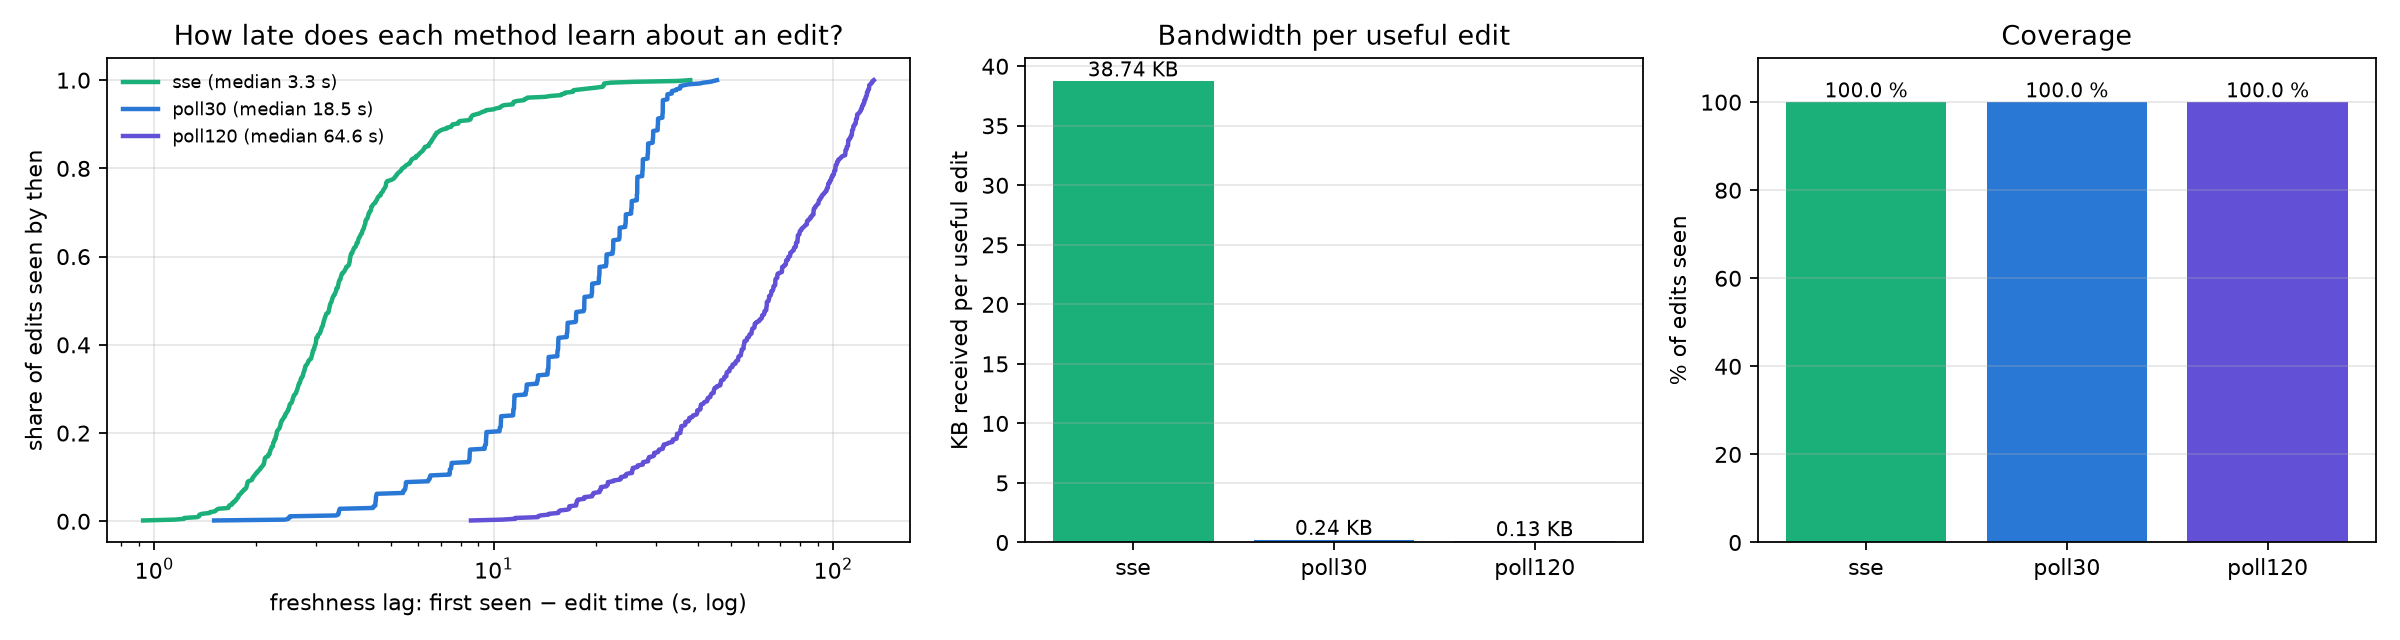

In [23]:
show(FIG / "sse_vs_poll_main.png", 1100)

- **Freshness:** SSE knew about an edit after a median **3.3 s** (p90 7.6 s); polling every 30 s → 18.5 s, every 120 s →
  64.6 s. With polling, the expected lag is about half the interval plus the request time — push removes the interval.
  (SSE's lag is measured against the edit's own timestamp, which has 1-second resolution, and includes Wikimedia's
  internal event pipeline.)
- **Bandwidth:** SSE received **31.9 MB in 10 min**, of which only **3.2 %** was useful: the stream carries all 145 wikis and
  was **not compressed** (`identity`). That is **38.7 KB per useful edit vs 0.24 KB** for 30-second polling (~160×).
- **Coverage:** all three saw 100 % of the 529 edits in the comparison window — the poll sizes were large enough for the
  edit rate (each poll's oldest returned edit was older than the previous poll).
- **Resilience:** after a 20 s forced disconnect, the `Last-Event-ID` resume delivered all 23 edits made during the outage.
- Side finding: the API answered the newest **100** edits in ~0.3 s (median) but **300** in ~9.3 s (500 in ~9 s in the benchmark):
  asking for less, more often, is much cheaper per request.

**Trade-off:** push wins on freshness (seconds instead of tens of seconds) and needs one connection; polling wins
massively on bandwidth here because we only need one wiki out of 145. Push is the right choice when freshness matters
(e.g. a live anti-vandalism dashboard); polling every 30–60 s is the efficient choice for periodic data collection.

## 7. Answer to research question 1

In [24]:
s = runs.groupby("method")
summary = pd.DataFrame({
    "KB on wire (app)": s.bandwidth_kb.mean().round(1),
    "KB incl. browser background (pcap)": (sp.groupby("method").target_kb.mean() + sp.groupby("method").other_kb.mean()).round(0),
    "requests": s.n_requests.mean().round(1),
    "time (s)": s.time_s.median().round(1),
    "freshness of newest edit (s)": s.freshness_newest_s.median().round(1),
    "fields available": pd.Series({"api": "all", "bs4": "all except rc_id, user_id", "selenium": "all except rc_id, user_id"}),
}).loc[["api", "bs4", "selenium"]]
summary

,KB on wire (app),KB incl. browser background (pcap),requests,time (s),freshness of newest edit (s),fields available
api,36.8,48.0,1.0,9.9,12.6,all
bs4,123.6,144.0,1.0,11.5,14.6,"all except rc_id, user_id"
selenium,656.2,10128.0,16.8,22.7,24.7,"all except rc_id, user_id"


**Recommendation: the MediaWiki Action API.** For the same 500 edits it moved the fewest bytes (≈ 37 KB app-level,
≈ 48 KB on the wire), needed one request, was the fastest and freshest, returned every field in clean JSON, and is the
interface Wikimedia asks automated clients to use. **BS4** is a reasonable fallback when no API exists (≈ 3–4× the bytes,
same server wait, ~1 s of parsing, loses internal IDs). **Selenium** is the most expensive by far: ~18× the API's bytes
for the page alone and ~200× when the browser's own background traffic is counted, 2–3× the time, and a heavy client —
it is only justified when a page needs JavaScript to show its data, which Recent Changes does not.
**SSE (bonus)** is the freshest of all (median 3.3 s vs 18.5 s for 30-second polling) but, for a single wiki, pays
~160× more bandwidth per useful edit — worth it only when seconds matter.

**Limits of this comparison:** one machine, one network, one time of day per experiment; the Wikimedia server time
(~9 s for this query) dominates every method's latency; Selenium ran with a fresh profile each time (worst case for
caching); Chrome's background traffic depends on browser version and flags.